# Lung Cancer Prediction

In [6]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
%matplotlib inline

In [7]:
import os
data_path = "cancer patient data sets.xlsx" if os.path.exists("cancer patient data sets.xlsx") else "C:\Python\ML\cancer patient data sets.xlsx"
df = pd.read_excel(data_path)
df

,Patient Id,Age,Gender,Air Pollution,Alcohol use,Dust Allergy,OccuPational Hazards,Genetic Risk,chronic Lung Disease,Balanced Diet,...,Fatigue,Weight Loss,Shortness of Breath,Wheezing,Swallowing Difficulty,Clubbing of Finger Nails,Frequent Cold,Dry Cough,Snoring,Level
0,P1,33,1,2,4,5,4,3,2,2,...,3,4,2,2,3,1,2,3,4,Low
1,P10,17,1,3,1,5,3,4,2,2,...,1,3,7,8,6,2,1,7,2,Medium
2,P100,35,1,4,5,6,5,5,4,6,...,8,7,9,2,1,4,6,7,2,High
3,P1000,37,1,7,7,7,7,6,7,7,...,4,2,3,1,4,5,6,7,5,High
4,P101,46,1,6,8,7,7,7,6,7,...,3,2,4,1,4,2,4,2,3,High
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,P995,44,1,6,7,7,7,7,6,7,...,5,3,2,7,8,2,4,5,3,High
996,P996,37,2,6,8,7,7,7,6,7,...,9,6,5,7,2,4,3,1,4,High
997,P997,25,2,4,5,6,5,5,4,6,...,8,7,9,2,1,4,6,7,2,High
998,P998,18,2,6,8,7,7,7,6,7,...,3,2,4,1,4,2,4,2,3,High


##         See the first 10 entries

In [8]:
df.head(10)

,Patient Id,Age,Gender,Air Pollution,Alcohol use,Dust Allergy,OccuPational Hazards,Genetic Risk,chronic Lung Disease,Balanced Diet,...,Fatigue,Weight Loss,Shortness of Breath,Wheezing,Swallowing Difficulty,Clubbing of Finger Nails,Frequent Cold,Dry Cough,Snoring,Level
0,P1,33,1,2,4,5,4,3,2,2,...,3,4,2,2,3,1,2,3,4,Low
1,P10,17,1,3,1,5,3,4,2,2,...,1,3,7,8,6,2,1,7,2,Medium
2,P100,35,1,4,5,6,5,5,4,6,...,8,7,9,2,1,4,6,7,2,High
3,P1000,37,1,7,7,7,7,6,7,7,...,4,2,3,1,4,5,6,7,5,High
4,P101,46,1,6,8,7,7,7,6,7,...,3,2,4,1,4,2,4,2,3,High
5,P102,35,1,4,5,6,5,5,4,6,...,8,7,9,2,1,4,6,7,2,High
6,P103,52,2,2,4,5,4,3,2,2,...,3,4,2,2,3,1,2,3,4,Low
7,P104,28,2,3,1,4,3,2,3,4,...,3,2,2,4,2,2,3,4,3,Low
8,P105,35,2,4,5,6,5,6,5,5,...,1,4,3,2,4,6,2,4,1,Medium
9,P106,46,1,2,3,4,2,4,3,3,...,1,2,4,6,5,4,2,1,5,Medium


## See the last 10 entries

In [9]:
df.tail(10)

,Patient Id,Age,Gender,Air Pollution,Alcohol use,Dust Allergy,OccuPational Hazards,Genetic Risk,chronic Lung Disease,Balanced Diet,...,Fatigue,Weight Loss,Shortness of Breath,Wheezing,Swallowing Difficulty,Clubbing of Finger Nails,Frequent Cold,Dry Cough,Snoring,Level
990,P990,49,1,6,5,6,5,5,4,6,...,8,7,9,2,1,4,6,7,2,High
991,P991,37,1,8,8,7,7,7,6,7,...,3,2,4,1,4,2,4,2,3,High
992,P992,26,2,7,7,7,7,7,6,7,...,2,7,6,7,6,7,2,3,1,High
993,P993,37,2,7,7,7,7,6,7,7,...,4,2,3,1,4,5,6,7,5,High
994,P994,33,1,6,7,7,7,7,7,6,...,8,5,7,6,7,8,7,6,2,High
995,P995,44,1,6,7,7,7,7,6,7,...,5,3,2,7,8,2,4,5,3,High
996,P996,37,2,6,8,7,7,7,6,7,...,9,6,5,7,2,4,3,1,4,High
997,P997,25,2,4,5,6,5,5,4,6,...,8,7,9,2,1,4,6,7,2,High
998,P998,18,2,6,8,7,7,7,6,7,...,3,2,4,1,4,2,4,2,3,High
999,P999,47,1,6,5,6,5,5,4,6,...,8,7,9,2,1,4,6,7,2,High


## See the name of all Columns in dataset

In [10]:
df.columns

Index(['Patient Id', 'Age', 'Gender', 'Air Pollution', 'Alcohol use',
       'Dust Allergy', 'OccuPational Hazards', 'Genetic Risk',
       'chronic Lung Disease', 'Balanced Diet', 'Obesity', 'Smoking',
       'Passive Smoker', 'Chest Pain', 'Coughing of Blood', 'Fatigue',
       'Weight Loss', 'Shortness of Breath', 'Wheezing',
       'Swallowing Difficulty', 'Clubbing of Finger Nails', 'Frequent Cold',
       'Dry Cough', 'Snoring', 'Level'],
      dtype='object')

## The Number of observations in the dataset?

In [11]:
df.shape[0]

1000

## The Number of Columns in the dataset

In [12]:
df.shape[1]

25

## The Information of each column

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Patient Id                1000 non-null   object
 1   Age                       1000 non-null   int64 
 2   Gender                    1000 non-null   int64 
 3   Air Pollution             1000 non-null   int64 
 4   Alcohol use               1000 non-null   int64 
 5   Dust Allergy              1000 non-null   int64 
 6   OccuPational Hazards      1000 non-null   int64 
 7   Genetic Risk              1000 non-null   int64 
 8   chronic Lung Disease      1000 non-null   int64 
 9   Balanced Diet             1000 non-null   int64 
 10  Obesity                   1000 non-null   int64 
 11  Smoking                   1000 non-null   int64 
 12  Passive Smoker            1000 non-null   int64 
 13  Chest Pain                1000 non-null   int64 
 14  Coughing of Blood        

## See only the Level column

In [14]:
df['Level']

0         Low
1      Medium
2        High
3        High
4        High
        ...  
995      High
996      High
997      High
998      High
999      High
Name: Level, Length: 1000, dtype: object

# The Most Frequent Level

In [15]:
df['Level'].value_counts()

Level
High      365
Medium    332
Low       303
Name: count, dtype: int64

# Summary of DataFrame.

In [16]:
df.describe()

,Age,Gender,Air Pollution,Alcohol use,Dust Allergy,OccuPational Hazards,Genetic Risk,chronic Lung Disease,Balanced Diet,Obesity,...,Coughing of Blood,Fatigue,Weight Loss,Shortness of Breath,Wheezing,Swallowing Difficulty,Clubbing of Finger Nails,Frequent Cold,Dry Cough,Snoring
count,1000.000000,1000.000000,1000.0000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,...,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,37.174000,1.402000,3.8400,4.563000,5.165000,4.840000,4.580000,4.380000,4.491000,4.465000,...,4.859000,3.856000,3.855000,4.240000,3.777000,3.746000,3.923000,3.536000,3.853000,2.926000
std,12.005493,0.490547,2.0304,2.620477,1.980833,2.107805,2.126999,1.848518,2.135528,2.124921,...,2.427965,2.244616,2.206546,2.285087,2.041921,2.270383,2.388048,1.832502,2.039007,1.474686
min,14.000000,1.000000,1.0000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,27.750000,1.000000,2.0000,2.000000,4.000000,3.000000,2.000000,3.000000,2.000000,3.000000,...,3.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
50%,36.000000,1.000000,3.0000,5.000000,6.000000,5.000000,5.000000,4.000000,4.000000,4.000000,...,4.000000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,3.000000,4.000000,3.000000
75%,45.000000,2.000000,6.0000,7.000000,7.000000,7.000000,7.000000,6.000000,7.000000,7.000000,...,7.000000,5.000000,6.000000,6.000000,5.000000,5.000000,5.000000,5.000000,6.000000,4.000000
max,73.000000,2.000000,8.0000,8.000000,8.000000,8.000000,7.000000,7.000000,7.000000,7.000000,...,9.000000,9.000000,8.000000,9.000000,8.000000,8.000000,9.000000,7.000000,7.000000,7.000000


# Summary of all Columns

In [17]:
df.describe(include="all")

,Patient Id,Age,Gender,Air Pollution,Alcohol use,Dust Allergy,OccuPational Hazards,Genetic Risk,chronic Lung Disease,Balanced Diet,...,Fatigue,Weight Loss,Shortness of Breath,Wheezing,Swallowing Difficulty,Clubbing of Finger Nails,Frequent Cold,Dry Cough,Snoring,Level
count,1000,1000.000000,1000.000000,1000.0000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,...,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000
unique,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3
top,P999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,High
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,365
mean,NaN,37.174000,1.402000,3.8400,4.563000,5.165000,4.840000,4.580000,4.380000,4.491000,...,3.856000,3.855000,4.240000,3.777000,3.746000,3.923000,3.536000,3.853000,2.926000,NaN
std,NaN,12.005493,0.490547,2.0304,2.620477,1.980833,2.107805,2.126999,1.848518,2.135528,...,2.244616,2.206546,2.285087,2.041921,2.270383,2.388048,1.832502,2.039007,1.474686,NaN
min,NaN,14.000000,1.000000,1.0000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,NaN
25%,NaN,27.750000,1.000000,2.0000,2.000000,4.000000,3.000000,2.000000,3.000000,2.000000,...,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,NaN
50%,NaN,36.000000,1.000000,3.0000,5.000000,6.000000,5.000000,5.000000,4.000000,4.000000,...,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,3.000000,4.000000,3.000000,NaN
75%,NaN,45.000000,2.000000,6.0000,7.000000,7.000000,7.000000,7.000000,6.000000,7.000000,...,5.000000,6.000000,6.000000,5.000000,5.000000,5.000000,5.000000,6.000000,4.000000,NaN


#  Summary of only age column

In [18]:
df['Age'].describe()

count    1000.000000
mean       37.174000
std        12.005493
min        14.000000
25%        27.750000
50%        36.000000
75%        45.000000
max        73.000000
Name: Age, dtype: float64

# The Mean Age of Patients

In [19]:
df['Age'].mean()

np.float64(37.174)

# Identify which columns have **missing values** and how many.

In [20]:
df.isnull().sum()

Patient Id                  0
Age                         0
Gender                      0
Air Pollution               0
Alcohol use                 0
Dust Allergy                0
OccuPational Hazards        0
Genetic Risk                0
chronic Lung Disease        0
Balanced Diet               0
Obesity                     0
Smoking                     0
Passive Smoker              0
Chest Pain                  0
Coughing of Blood           0
Fatigue                     0
Weight Loss                 0
Shortness of Breath         0
Wheezing                    0
Swallowing Difficulty       0
Clubbing of Finger Nails    0
Frequent Cold               0
Dry Cough                   0
Snoring                     0
Level                       0
dtype: int64

# See the **data type** of each column using `.dtypes`.


In [21]:
df.dtypes

Patient Id                  object
Age                          int64
Gender                       int64
Air Pollution                int64
Alcohol use                  int64
Dust Allergy                 int64
OccuPational Hazards         int64
Genetic Risk                 int64
chronic Lung Disease         int64
Balanced Diet                int64
Obesity                      int64
Smoking                      int64
Passive Smoker               int64
Chest Pain                   int64
Coughing of Blood            int64
Fatigue                      int64
Weight Loss                  int64
Shortness of Breath          int64
Wheezing                     int64
Swallowing Difficulty        int64
Clubbing of Finger Nails     int64
Frequent Cold                int64
Dry Cough                    int64
Snoring                      int64
Level                       object
dtype: object

# Check how many **duplicate rows** exist in the DataFrame.


In [22]:
int(df.duplicated().sum())

0

# Rename the column `Level` to `Level_usd`.


In [23]:
df.rename(columns={'Level':'Level_usd'})

,Patient Id,Age,Gender,Air Pollution,Alcohol use,Dust Allergy,OccuPational Hazards,Genetic Risk,chronic Lung Disease,Balanced Diet,...,Fatigue,Weight Loss,Shortness of Breath,Wheezing,Swallowing Difficulty,Clubbing of Finger Nails,Frequent Cold,Dry Cough,Snoring,Level_usd
0,P1,33,1,2,4,5,4,3,2,2,...,3,4,2,2,3,1,2,3,4,Low
1,P10,17,1,3,1,5,3,4,2,2,...,1,3,7,8,6,2,1,7,2,Medium
2,P100,35,1,4,5,6,5,5,4,6,...,8,7,9,2,1,4,6,7,2,High
3,P1000,37,1,7,7,7,7,6,7,7,...,4,2,3,1,4,5,6,7,5,High
4,P101,46,1,6,8,7,7,7,6,7,...,3,2,4,1,4,2,4,2,3,High
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,P995,44,1,6,7,7,7,7,6,7,...,5,3,2,7,8,2,4,5,3,High
996,P996,37,2,6,8,7,7,7,6,7,...,9,6,5,7,2,4,3,1,4,High
997,P997,25,2,4,5,6,5,5,4,6,...,8,7,9,2,1,4,6,7,2,High
998,P998,18,2,6,8,7,7,7,6,7,...,3,2,4,1,4,2,4,2,3,High


# Number of unique Genetic Risk

In [24]:
df['Genetic Risk'].nunique()

7

# Max Cancer Age

In [25]:
c=df.sort_values(['Age'],ascending=False)
c.head(1)

,Patient Id,Age,Gender,Air Pollution,Alcohol use,Dust Allergy,OccuPational Hazards,Genetic Risk,chronic Lung Disease,Balanced Diet,...,Fatigue,Weight Loss,Shortness of Breath,Wheezing,Swallowing Difficulty,Clubbing of Finger Nails,Frequent Cold,Dry Cough,Snoring,Level
459,P511,73,1,5,6,6,5,6,5,6,...,4,3,6,2,1,2,1,6,2,Medium


## Display Age and Gender columns and only first 10 entries

In [26]:
df[['Age','Gender']].head(10)

,Age,Gender
0,33,1
1,17,1
2,35,1
3,37,1
4,46,1
5,35,1
6,52,2
7,28,2
8,35,2
9,46,1


# Most common level in dataset

In [27]:
df['Level'].value_counts().idxmax()

'High'

# Select rows 1 to 10 and the first 4 columns.

In [28]:
df.iloc[1:11,1:5]

,Age,Gender,Air Pollution,Alcohol use
1,17,1,3,1
2,35,1,4,5
3,37,1,7,7
4,46,1,6,8
5,35,1,4,5
6,52,2,2,4
7,28,2,3,1
8,35,2,4,5
9,46,1,2,3
10,44,1,6,7


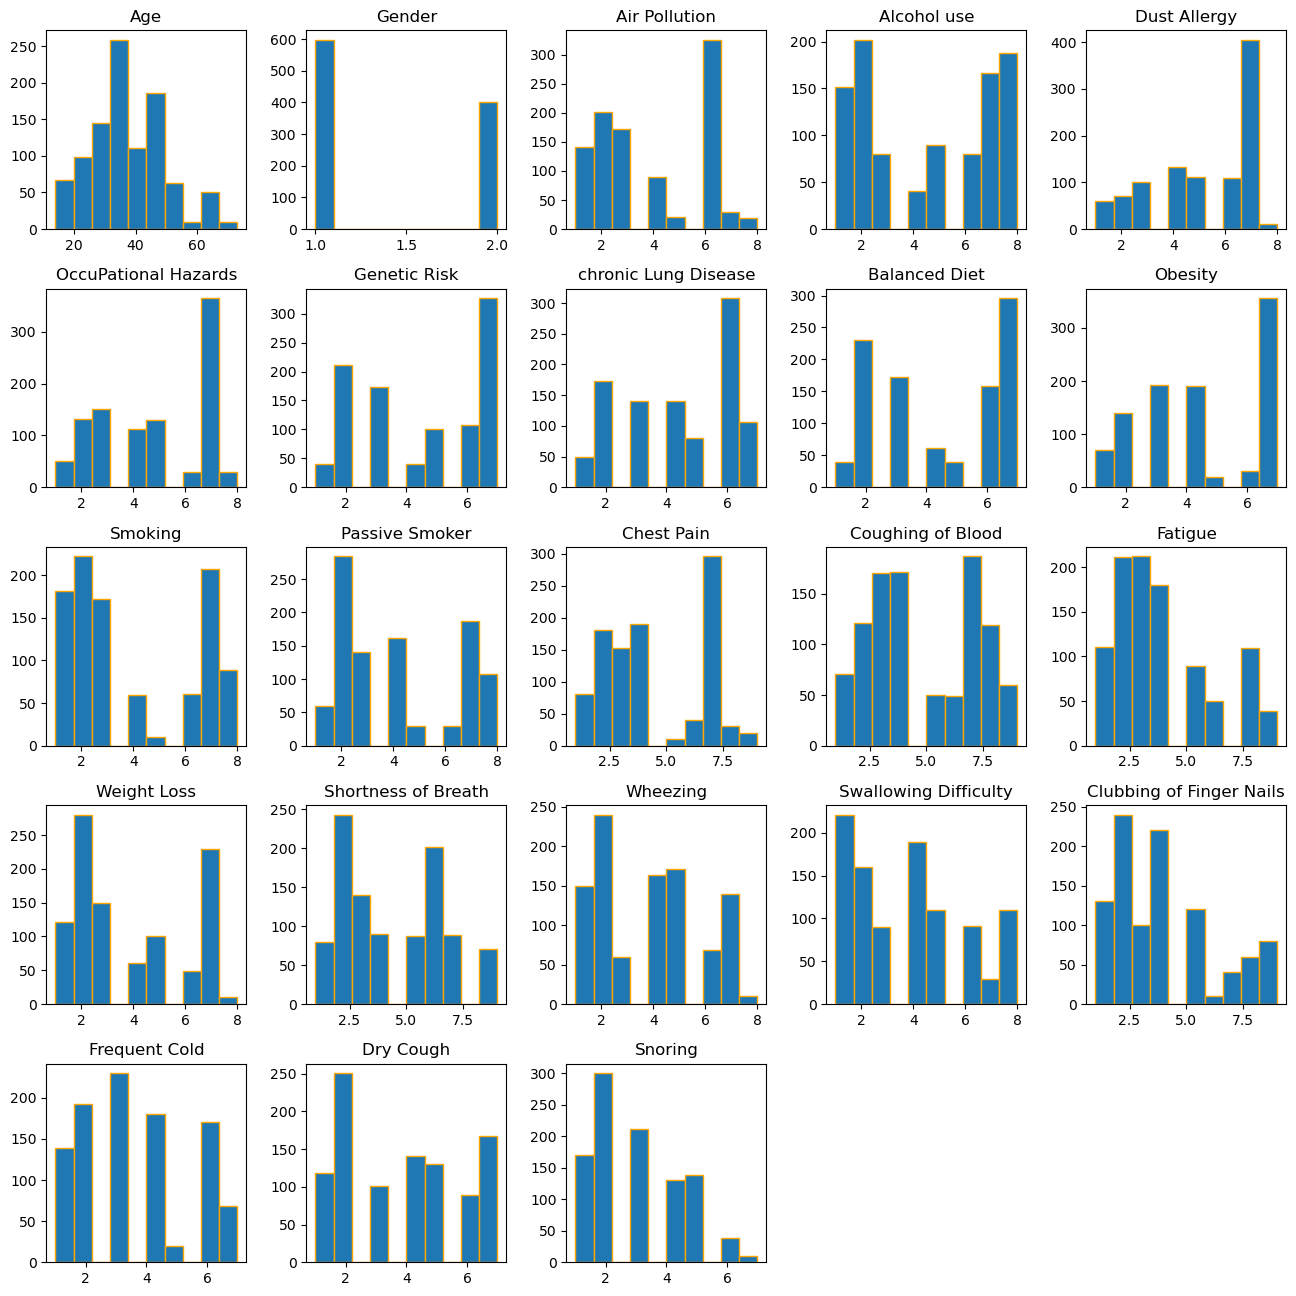

In [29]:
df.hist(edgecolor='orange' ,grid = False, figsize=(16, 16))
plt.show()

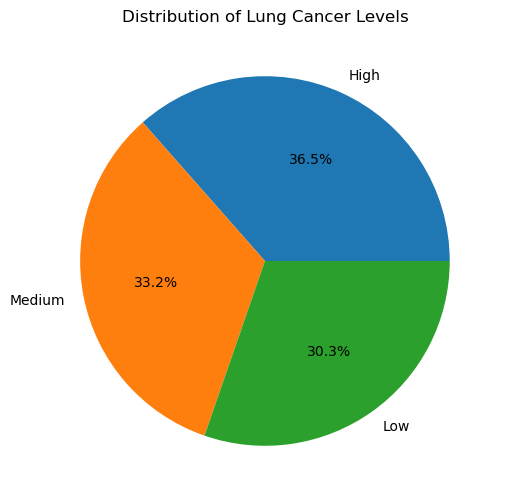

In [30]:
level_count = df["Level"].value_counts()

plt.figure(figsize=(6,6))
plt.pie(level_count,
        labels=level_count.index,
        autopct="%1.1f%%")

plt.title("Distribution of Lung Cancer Levels")
plt.show()

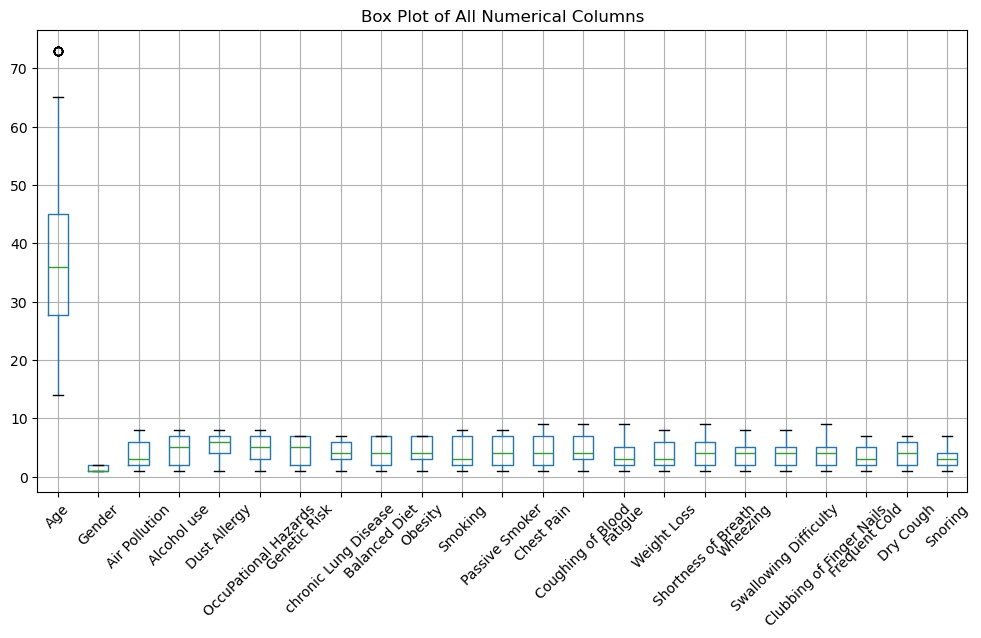

In [31]:
import matplotlib.pyplot as plt

df.boxplot(figsize=(12, 6))
plt.title("Box Plot of All Numerical Columns")
plt.xticks(rotation=45)
plt.show()

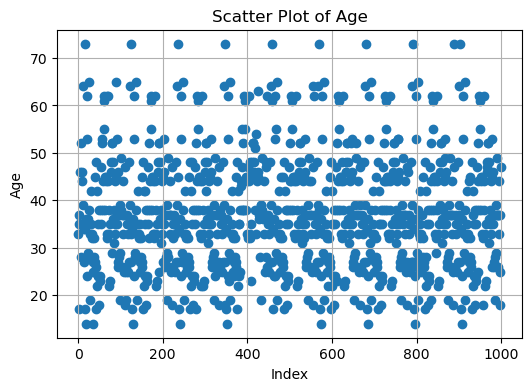

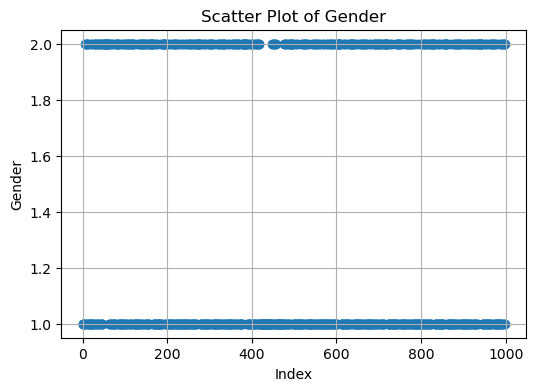

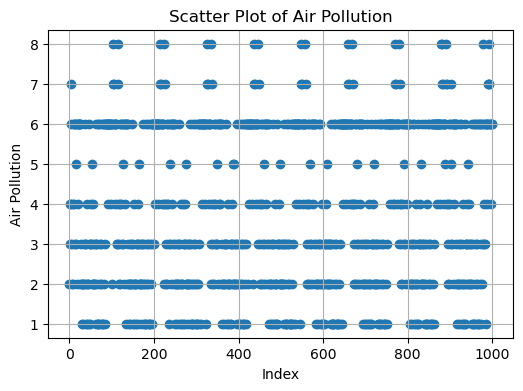

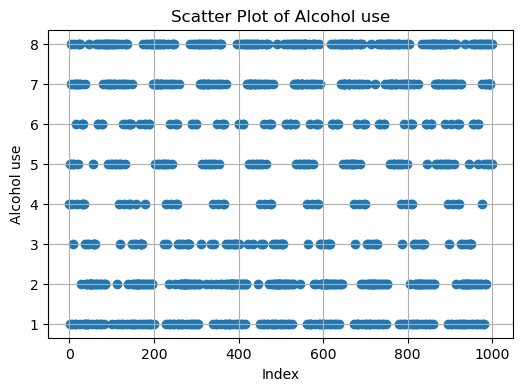

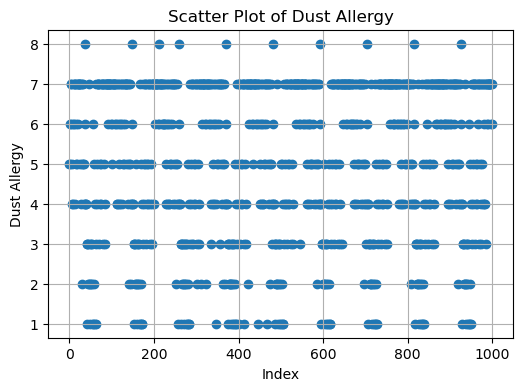

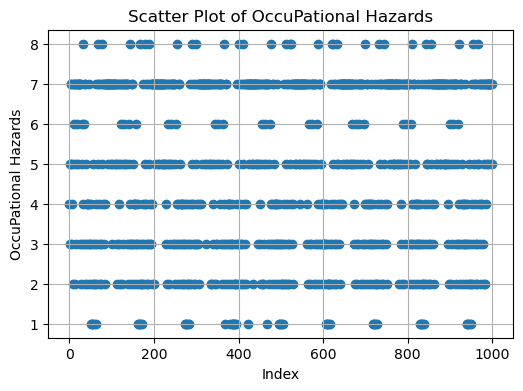

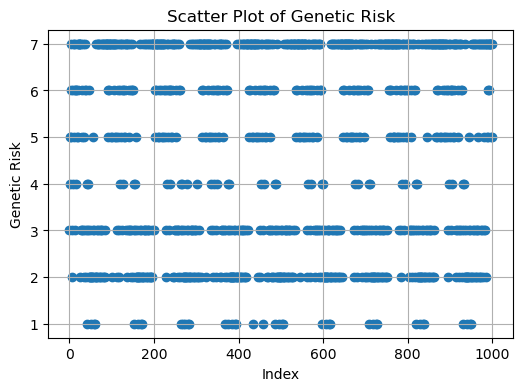

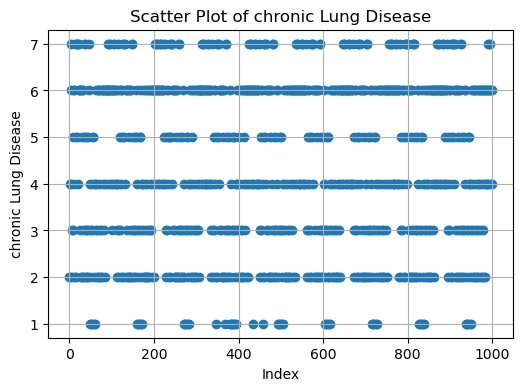

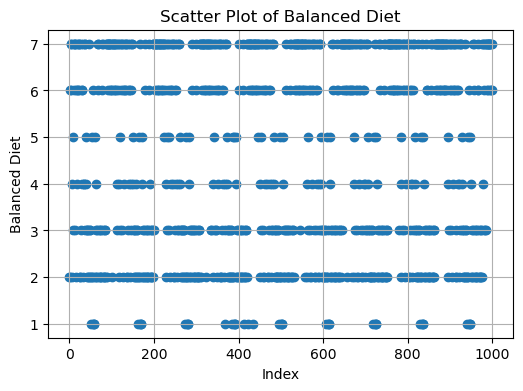

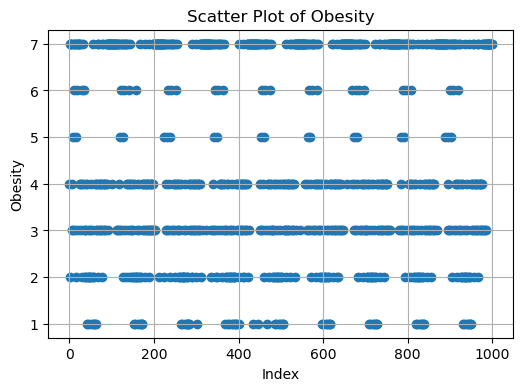

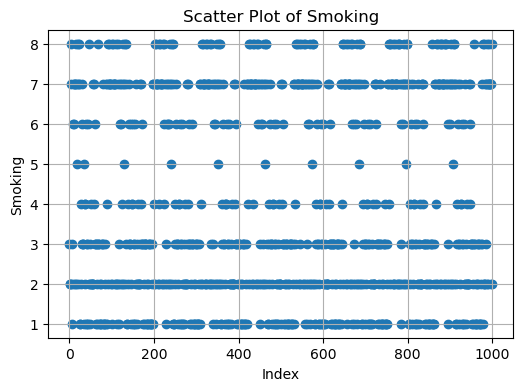

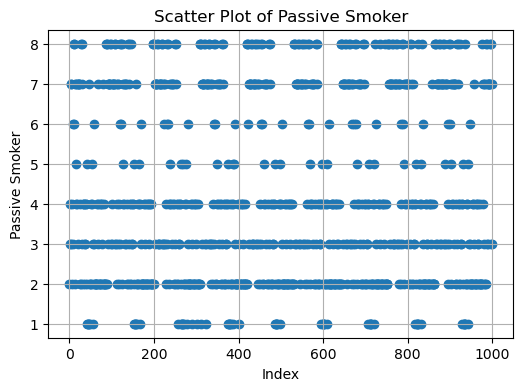

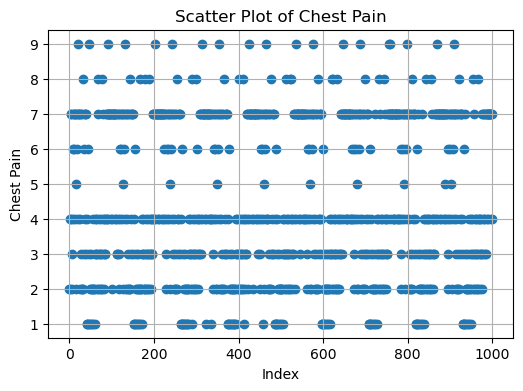

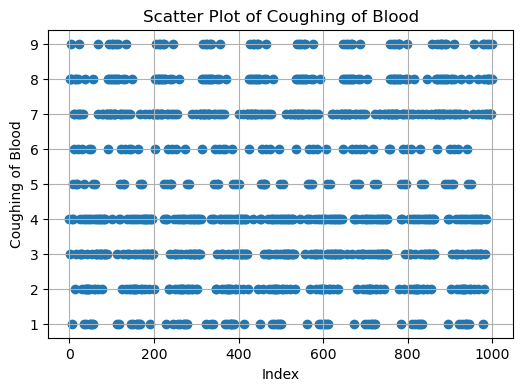

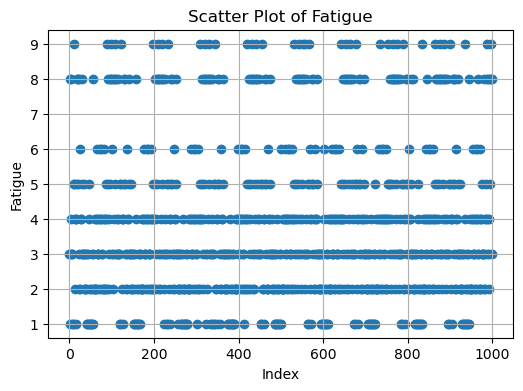

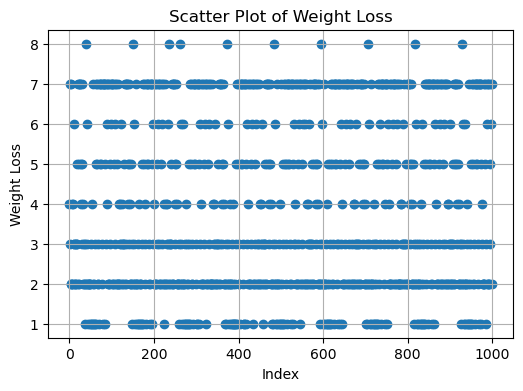

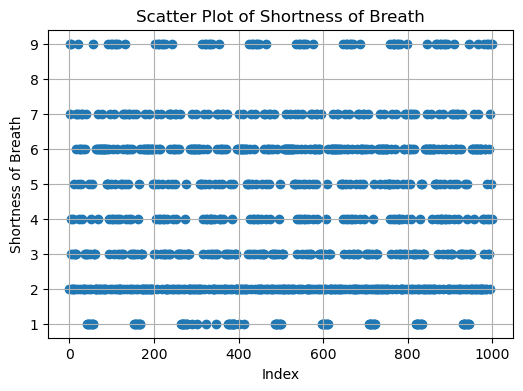

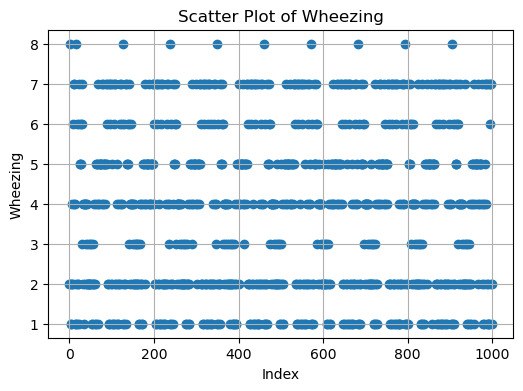

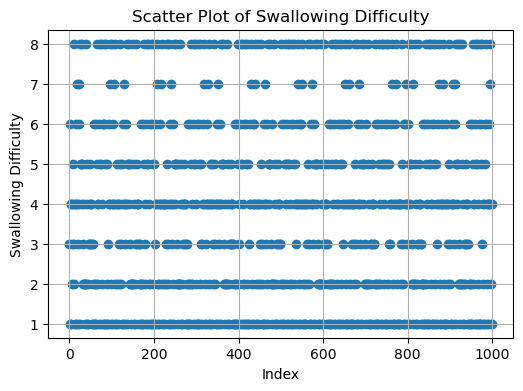

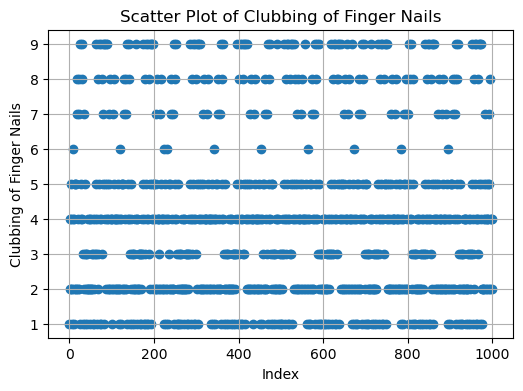

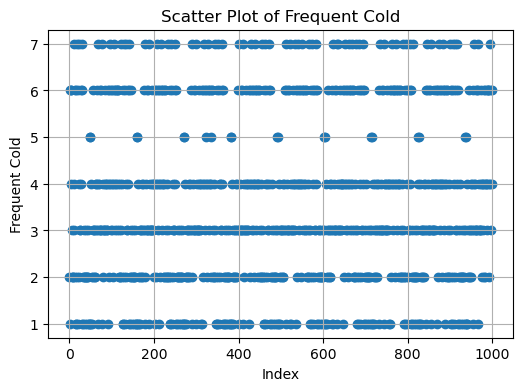

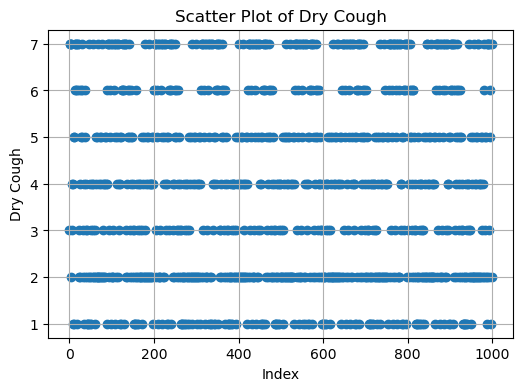

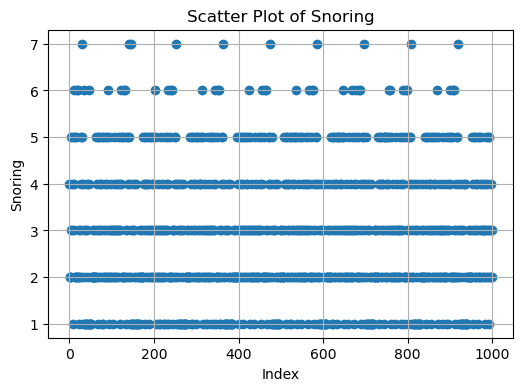

In [32]:
import matplotlib.pyplot as plt

numeric_cols = df.select_dtypes(include='number').columns

for col in numeric_cols:
    plt.figure(figsize=(6,4))
    plt.scatter(df.index, df[col])
    plt.xlabel("Index")
    plt.ylabel(col)
    plt.title(f"Scatter Plot of {col}")
    plt.grid(True)
    plt.show()

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.scatter(df['Age'], df['Smoking'])


In [34]:
plt.scatter(df['Age'],df['Smoking'])

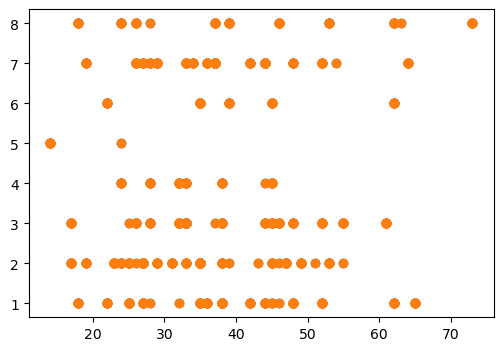

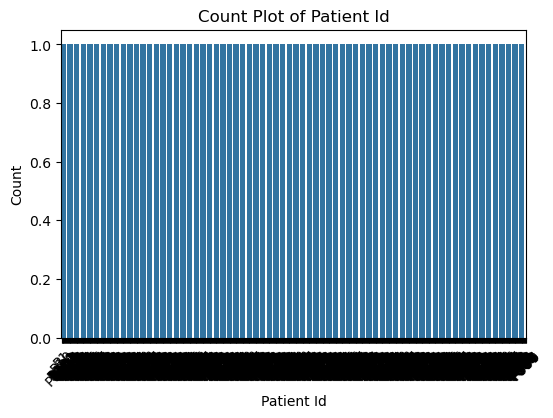

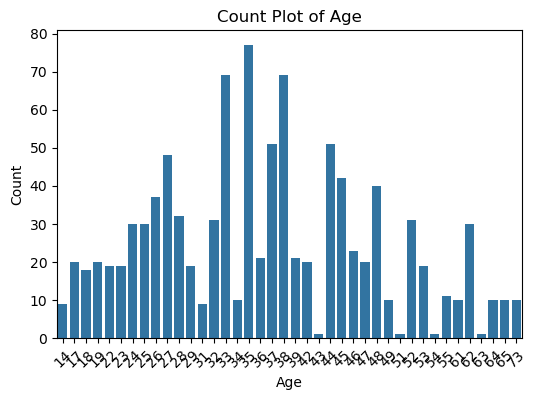

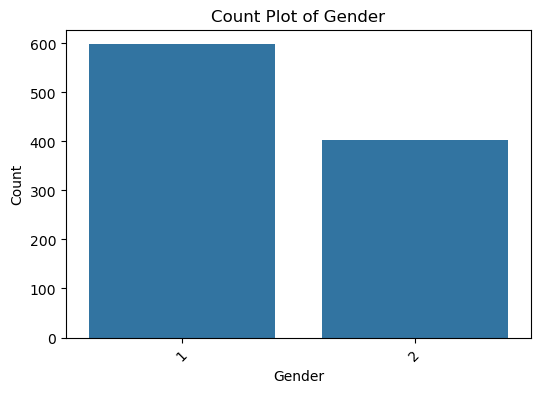

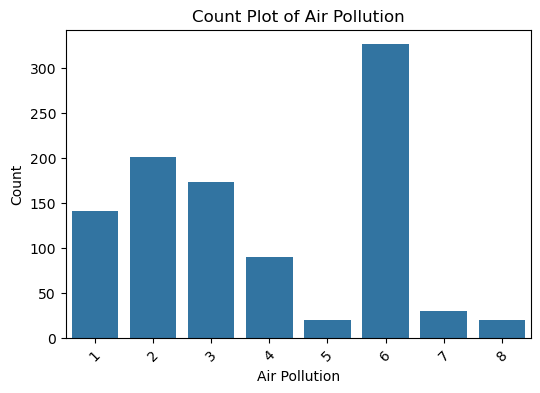

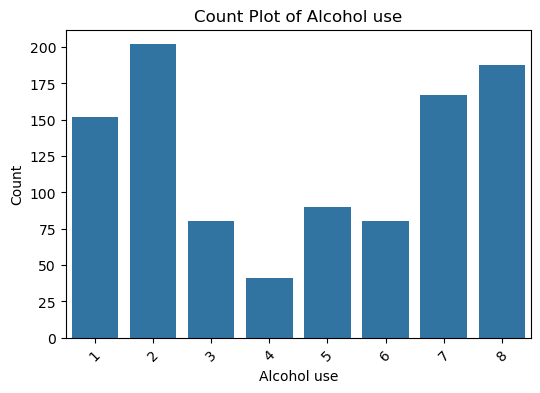

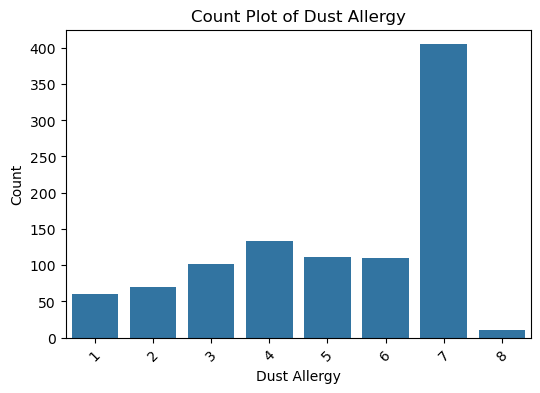

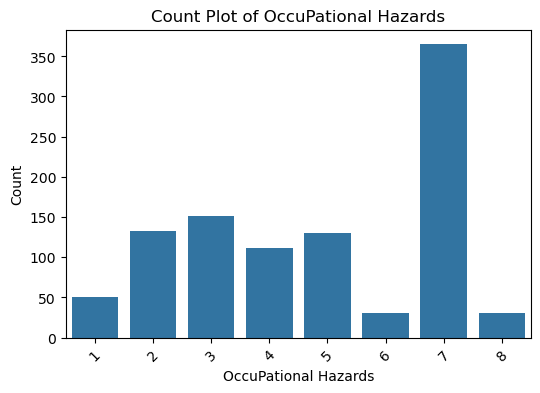

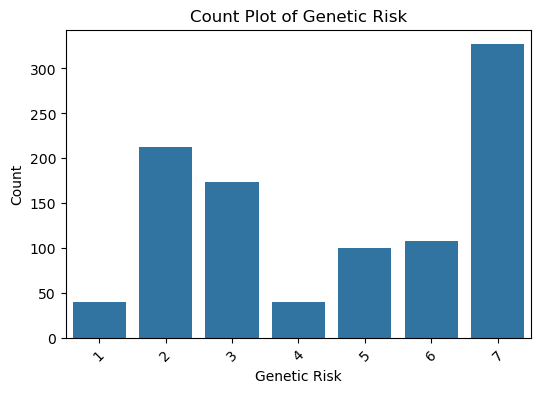

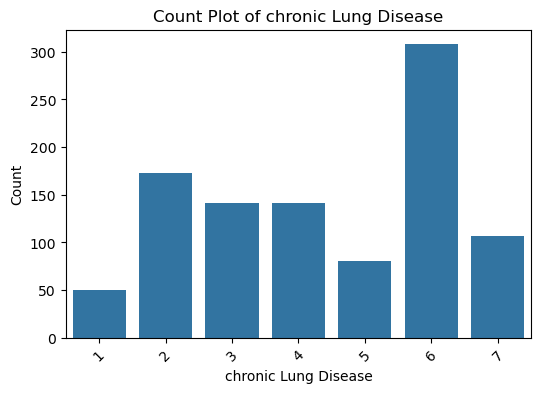

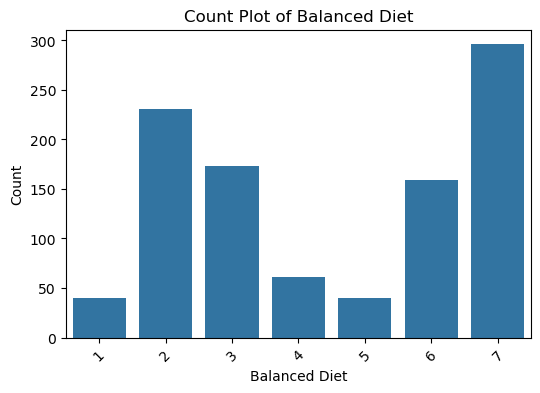

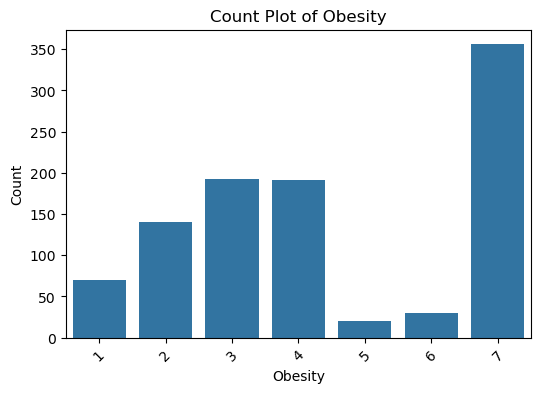

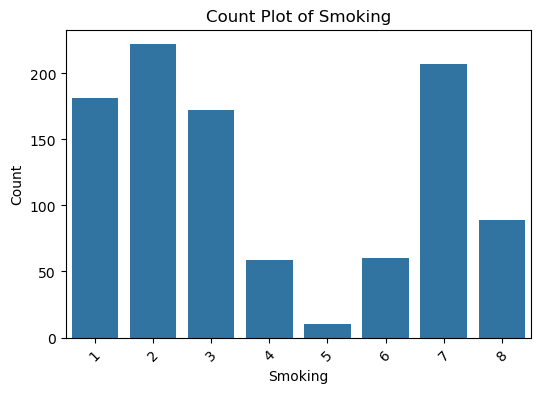

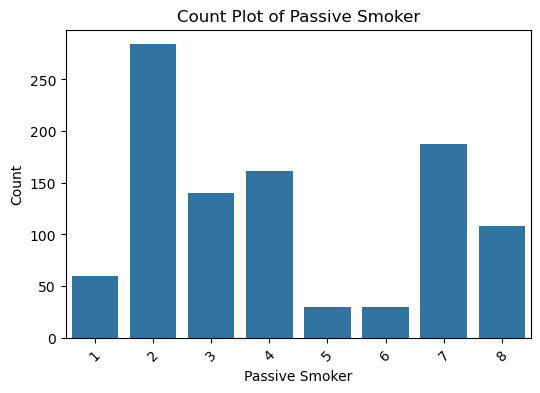

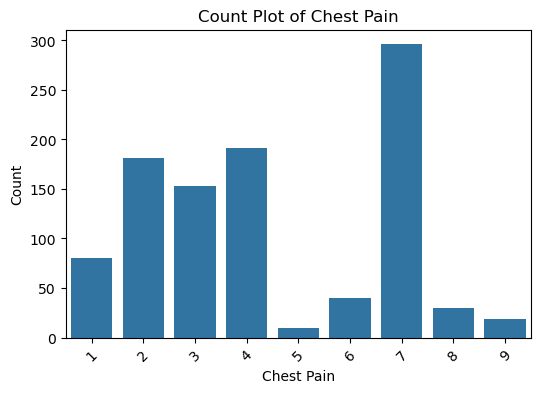

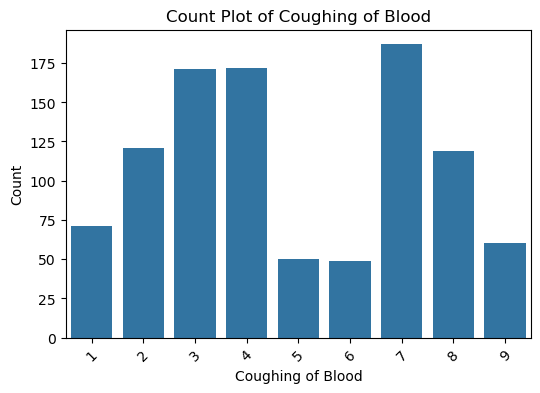

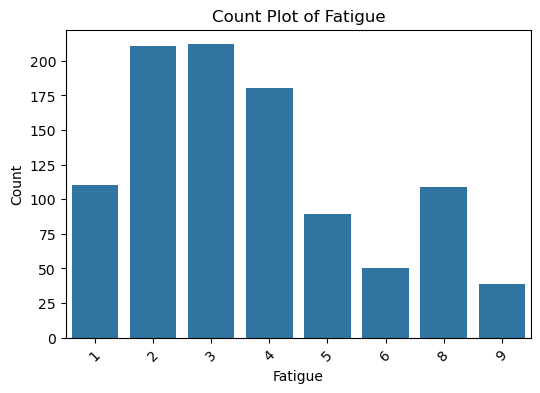

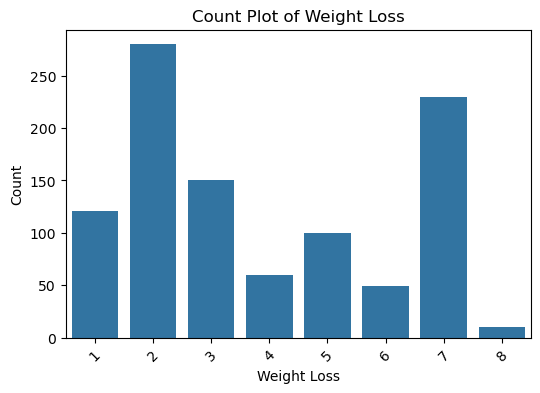

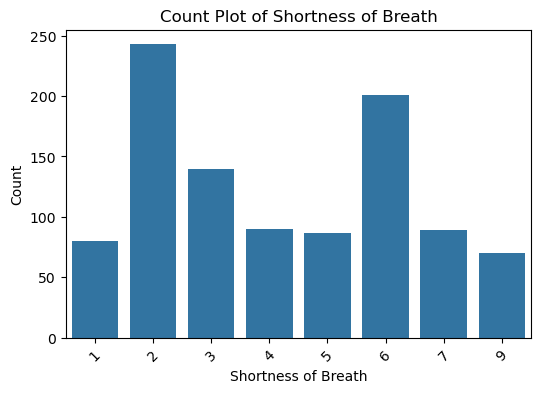

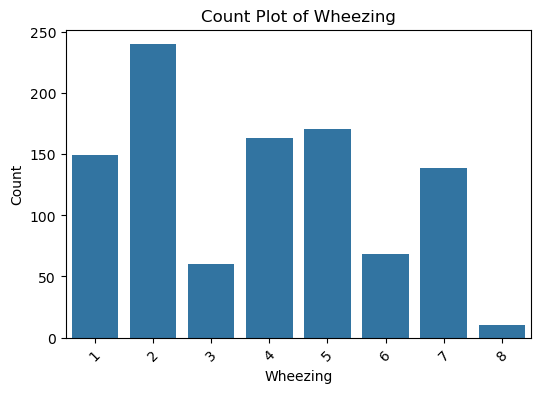

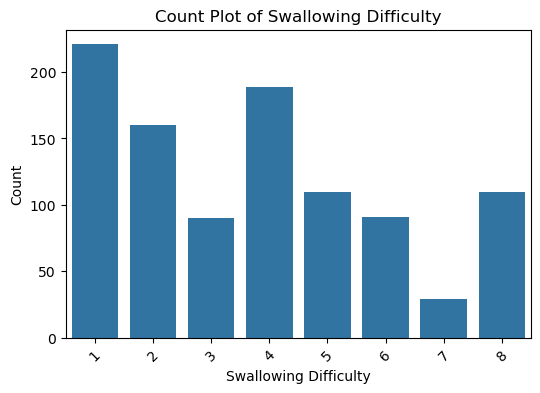

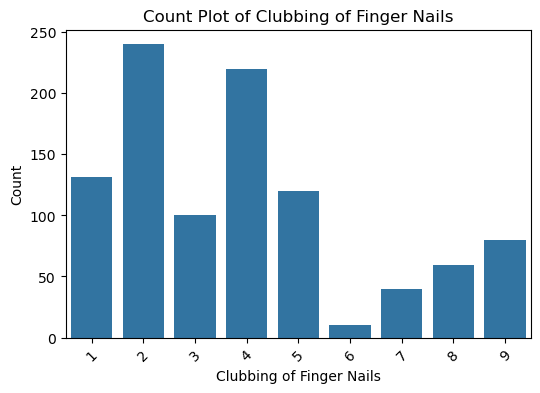

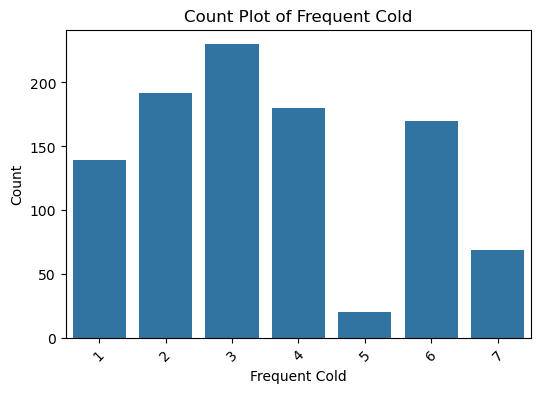

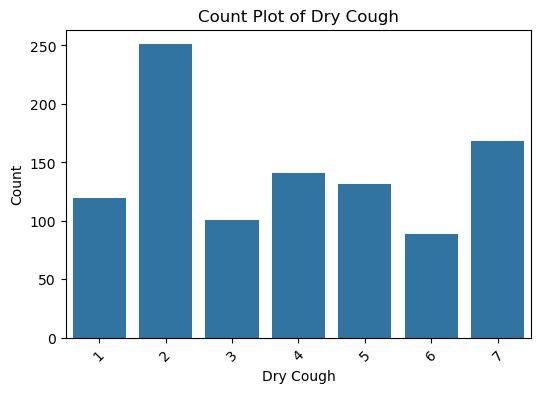

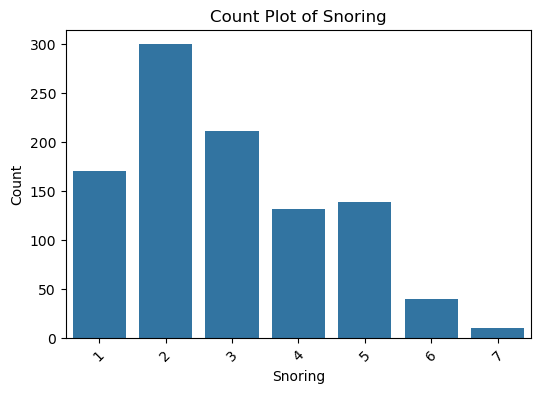

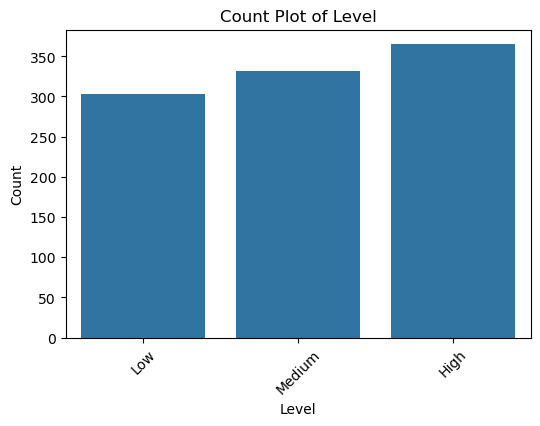

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in df.columns:
    plt.figure(figsize=(6,4))
    sns.countplot(x=col, data=df)
    plt.title(f'Count Plot of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45)
    plt.show()

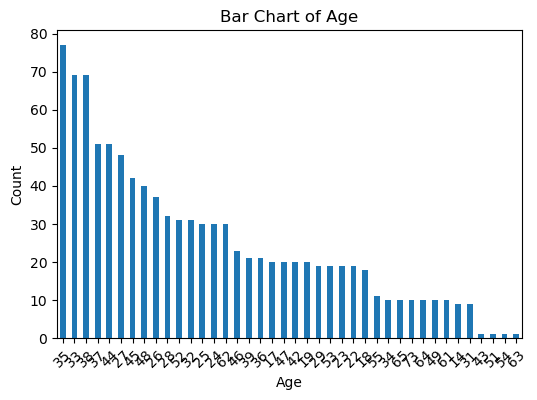

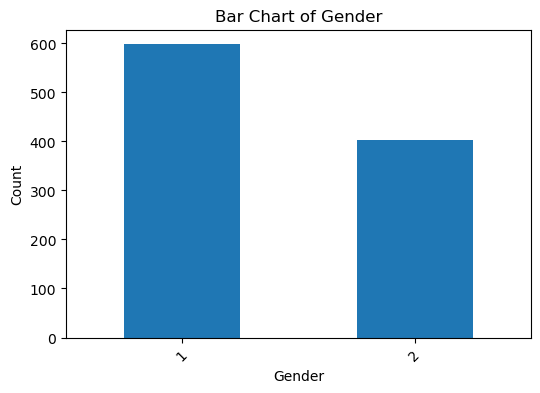

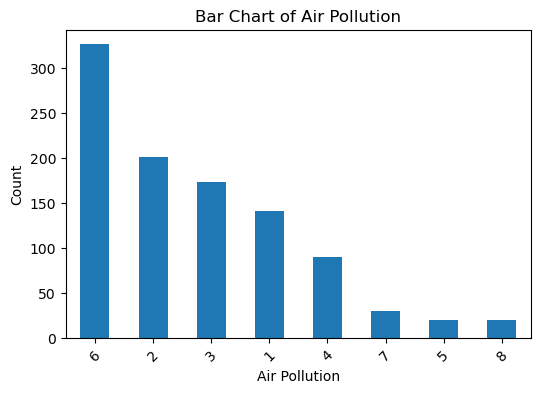

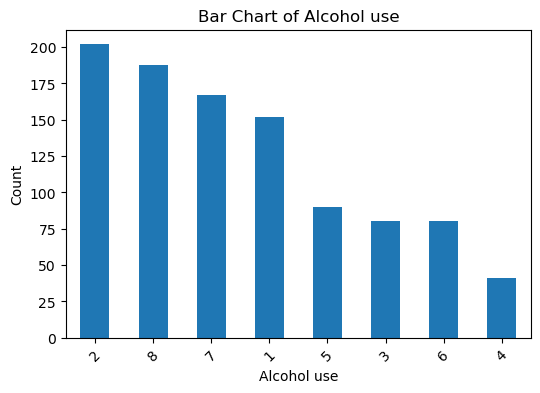

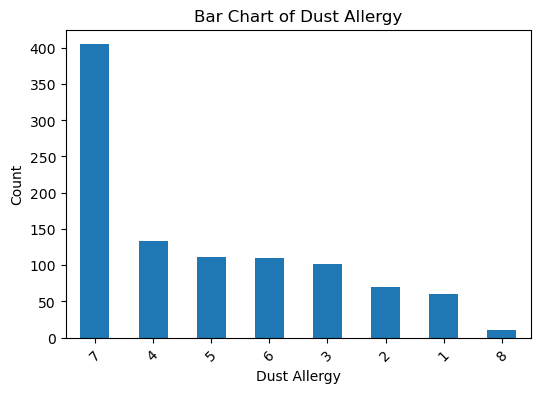

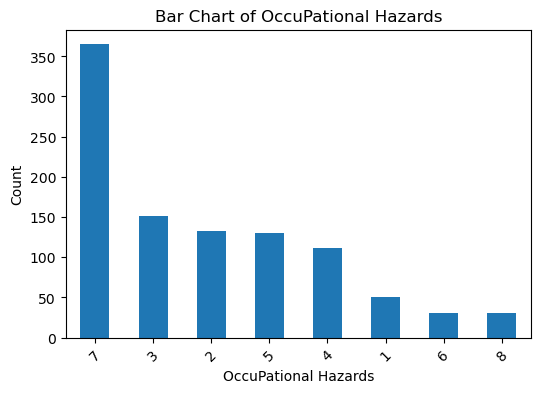

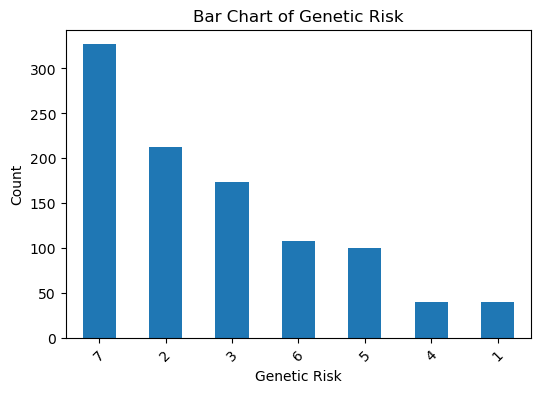

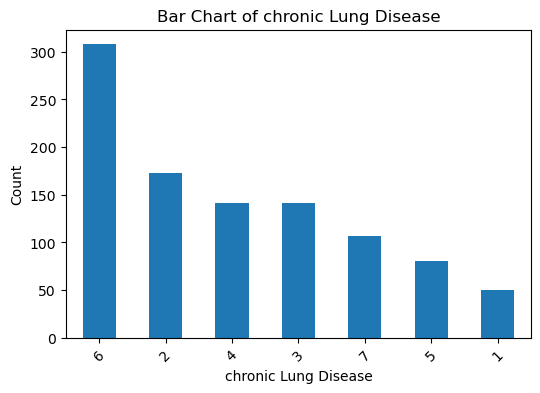

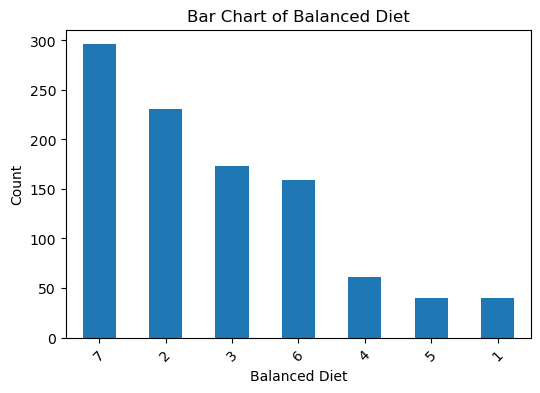

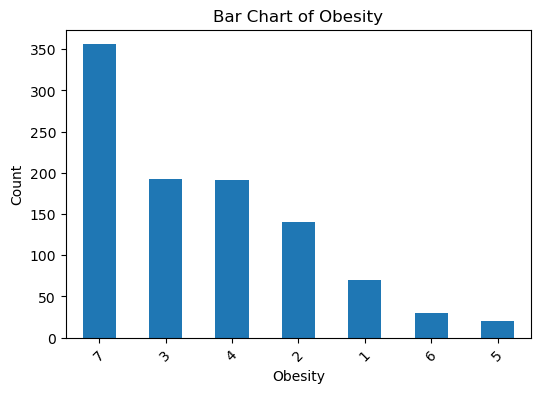

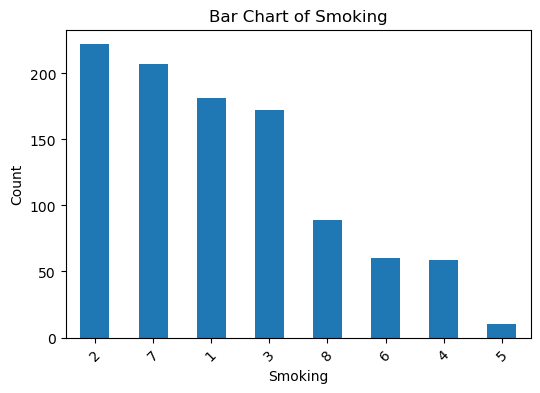

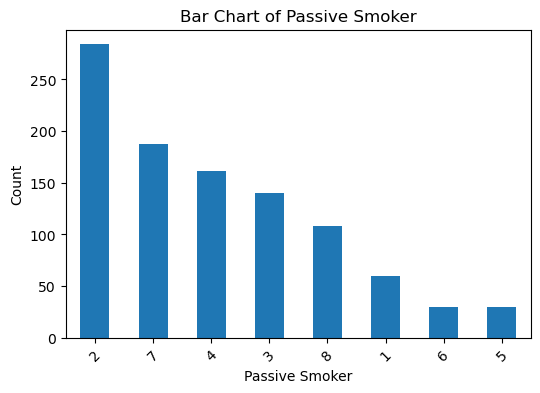

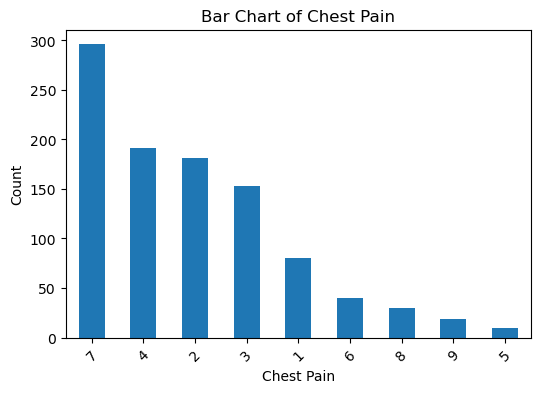

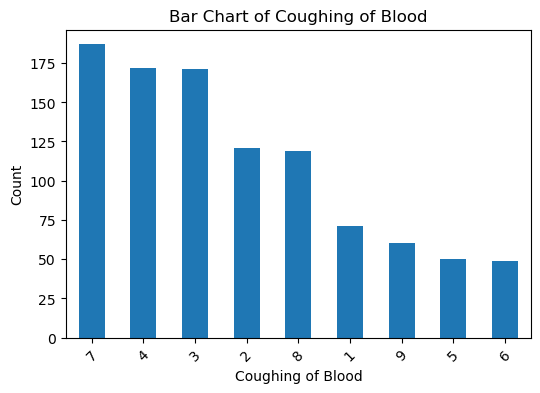

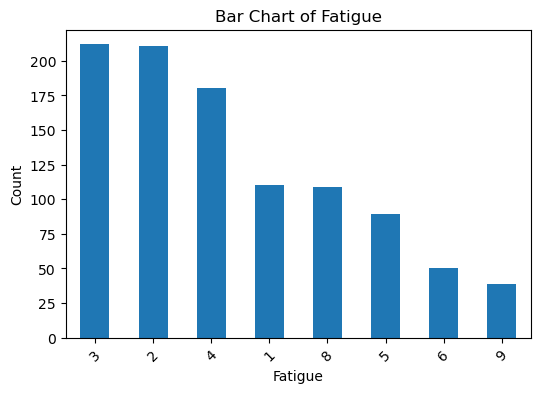

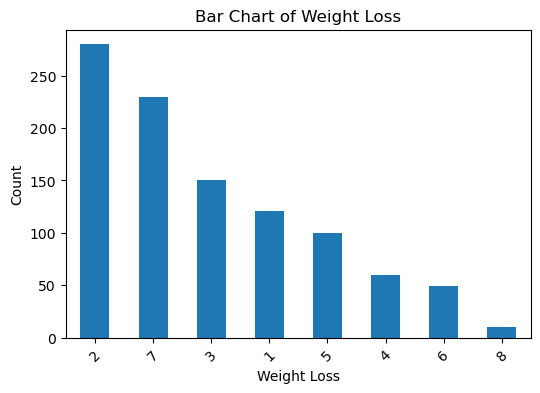

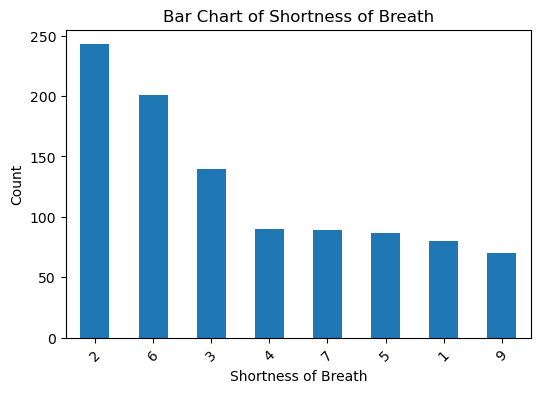

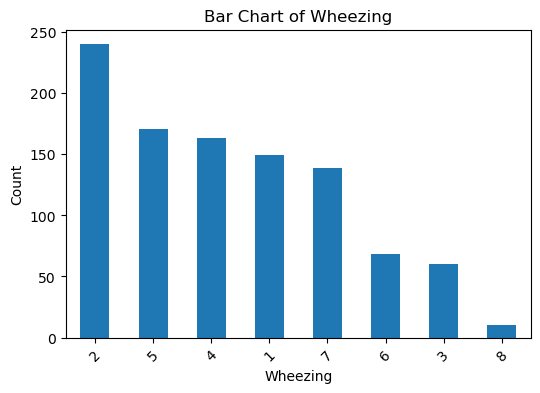

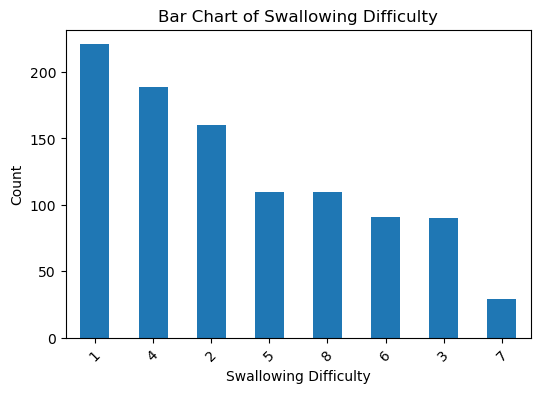

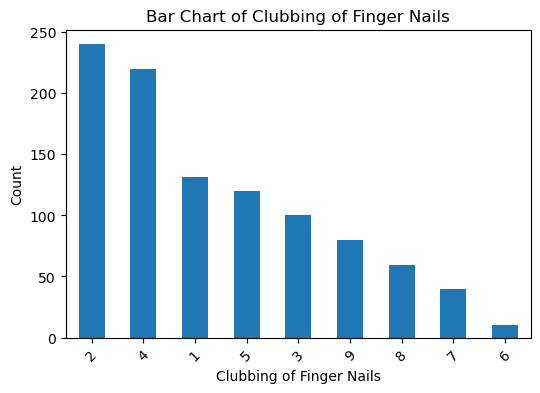

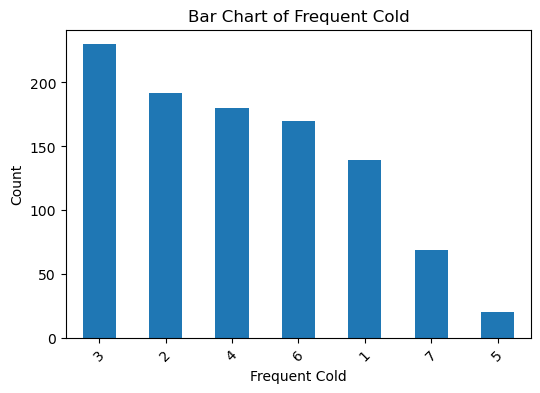

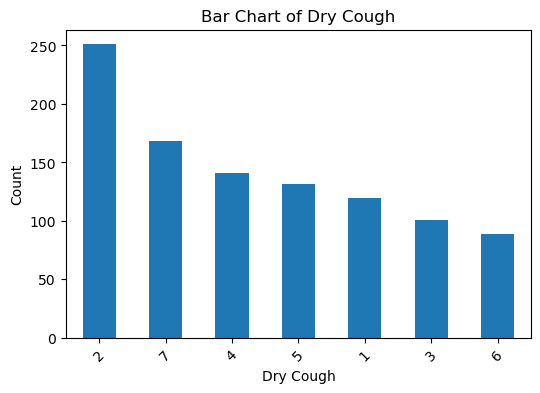

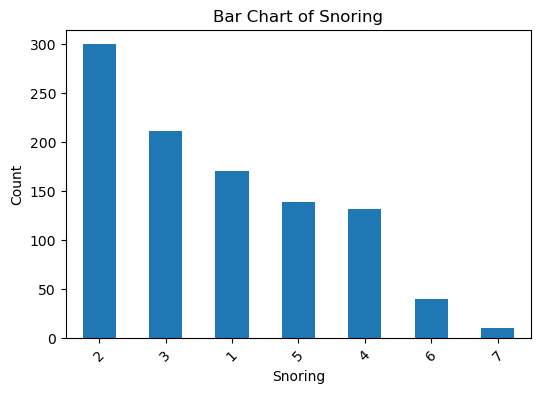

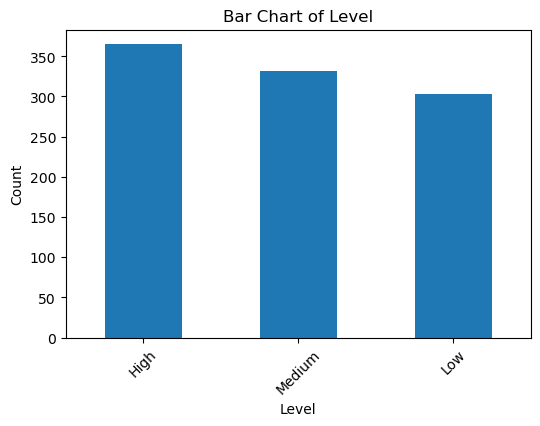

In [36]:
import matplotlib.pyplot as plt

for col in df.columns:
    if col != 'Patient Id':  
        plt.figure(figsize=(6,4))
        df[col].value_counts().plot(kind='bar')
        plt.title(f'Bar Chart of {col}')
        plt.xlabel(col)
        plt.ylabel('Count')
        plt.xticks(rotation=45)
        plt.show()

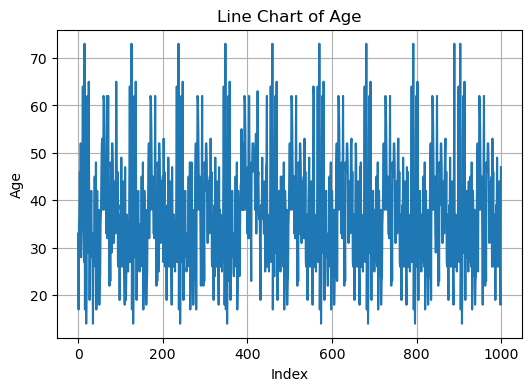

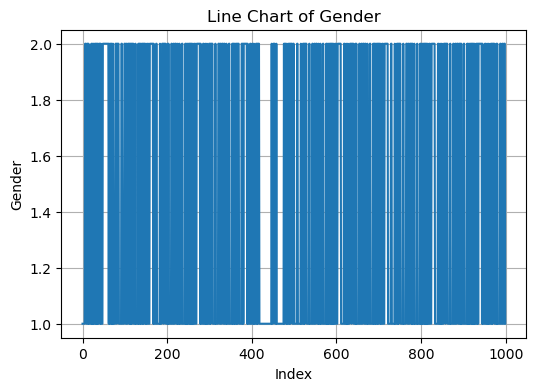

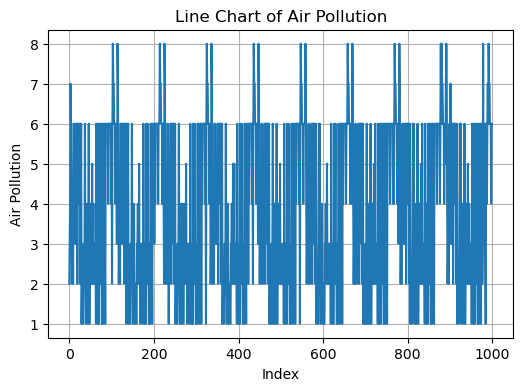

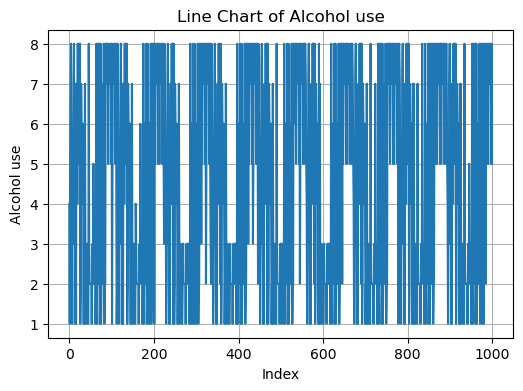

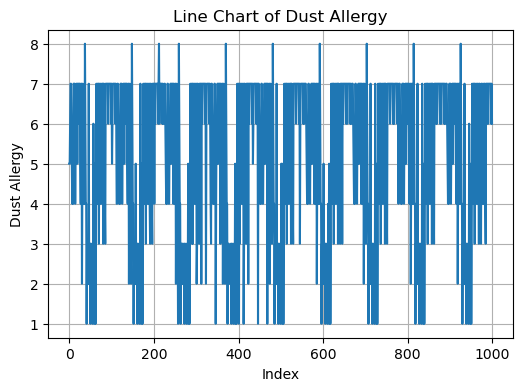

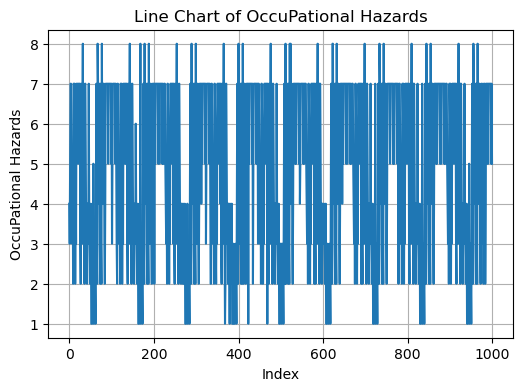

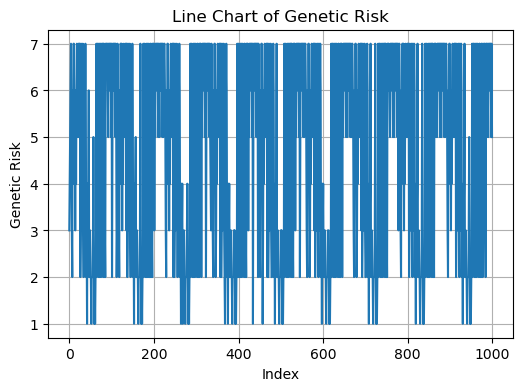

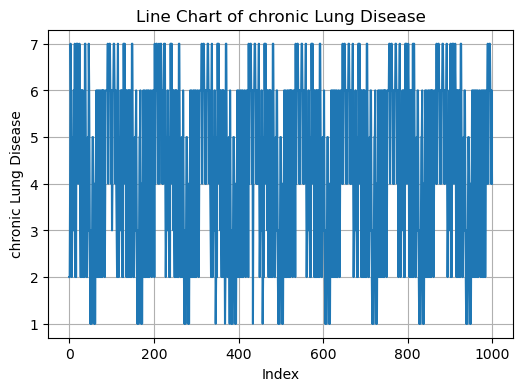

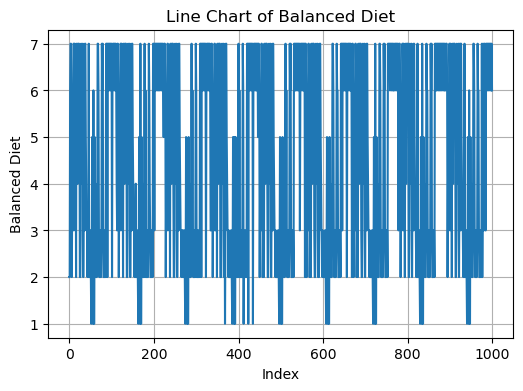

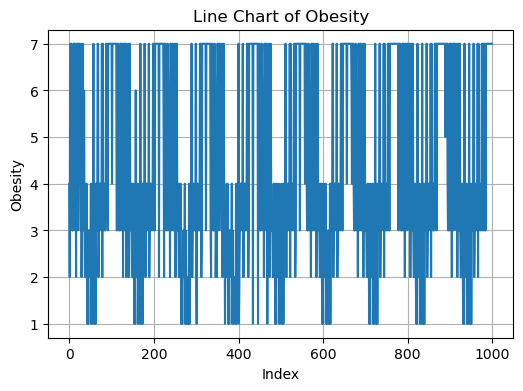

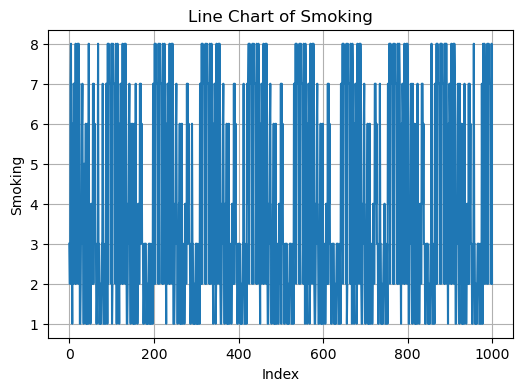

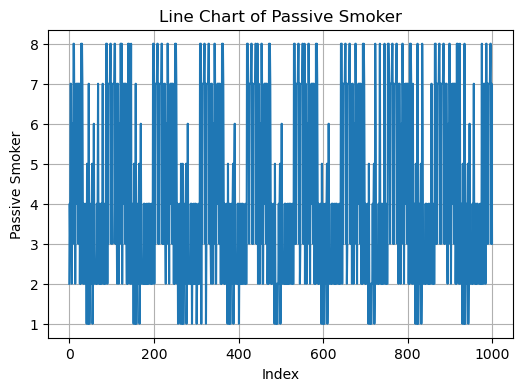

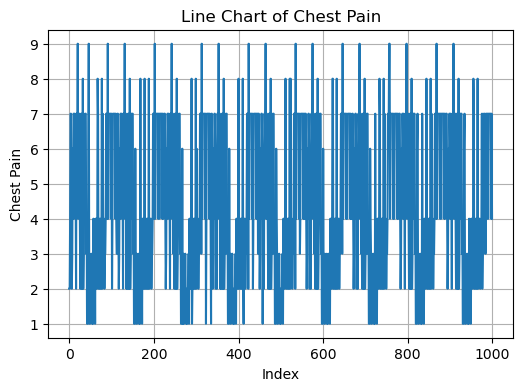

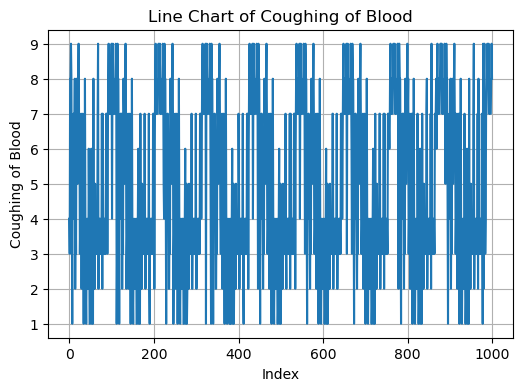

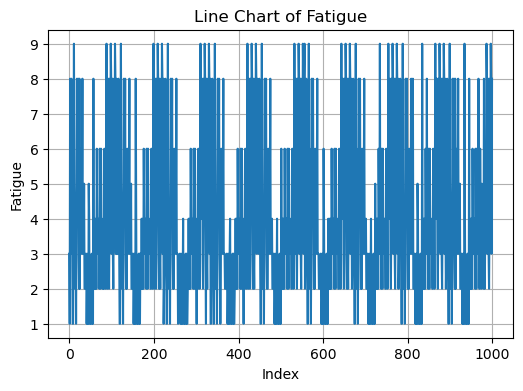

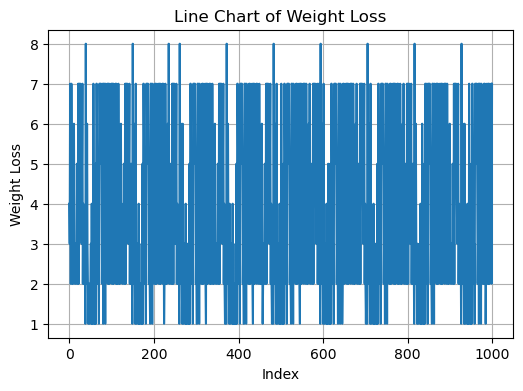

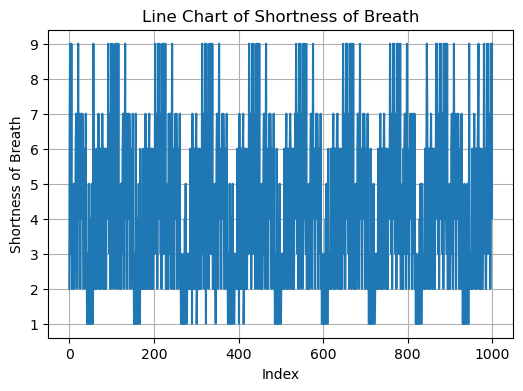

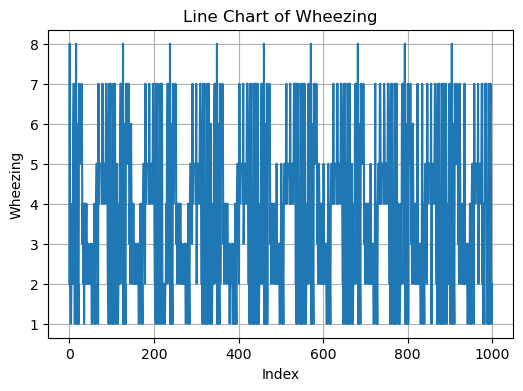

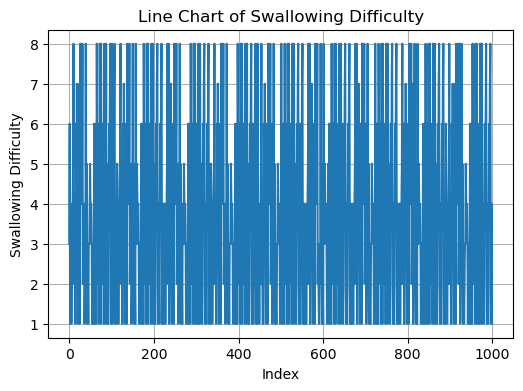

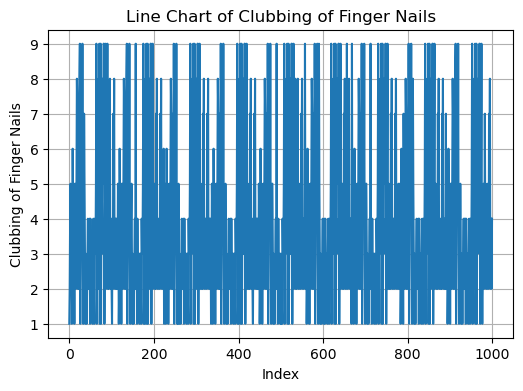

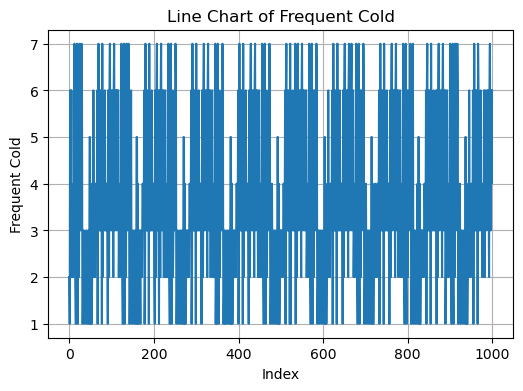

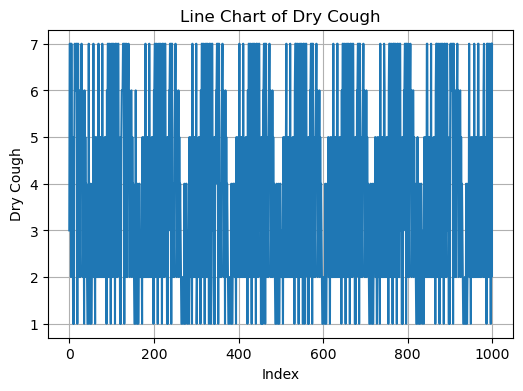

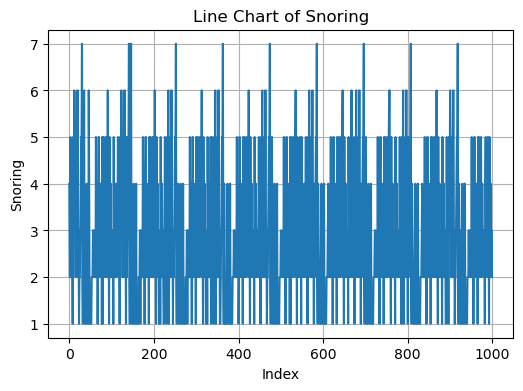

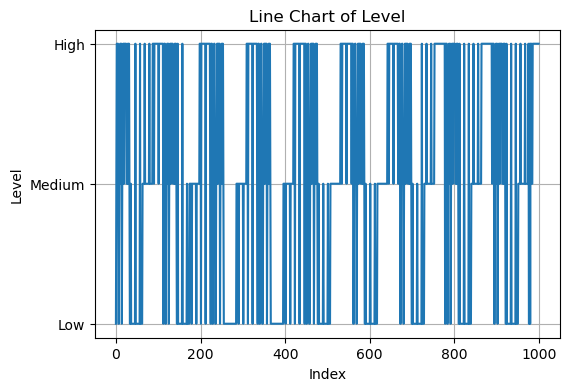

In [37]:
import matplotlib.pyplot as plt

for col in df.columns:
    if col != 'Patient Id':   
        plt.figure(figsize=(6,4))
        plt.plot(df[col])
        plt.title(f'Line Chart of {col}')
        plt.xlabel('Index')
        plt.ylabel(col)
        plt.grid(True)
        plt.show()

In [38]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

df[['Age']] = scaler.fit_transform(df[['Age']])
df

,Patient Id,Age,Gender,Air Pollution,Alcohol use,Dust Allergy,OccuPational Hazards,Genetic Risk,chronic Lung Disease,Balanced Diet,...,Fatigue,Weight Loss,Shortness of Breath,Wheezing,Swallowing Difficulty,Clubbing of Finger Nails,Frequent Cold,Dry Cough,Snoring,Level
0,P1,0.322034,1,2,4,5,4,3,2,2,...,3,4,2,2,3,1,2,3,4,Low
1,P10,0.050847,1,3,1,5,3,4,2,2,...,1,3,7,8,6,2,1,7,2,Medium
2,P100,0.355932,1,4,5,6,5,5,4,6,...,8,7,9,2,1,4,6,7,2,High
3,P1000,0.389831,1,7,7,7,7,6,7,7,...,4,2,3,1,4,5,6,7,5,High
4,P101,0.542373,1,6,8,7,7,7,6,7,...,3,2,4,1,4,2,4,2,3,High
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,P995,0.508475,1,6,7,7,7,7,6,7,...,5,3,2,7,8,2,4,5,3,High
996,P996,0.389831,2,6,8,7,7,7,6,7,...,9,6,5,7,2,4,3,1,4,High
997,P997,0.186441,2,4,5,6,5,5,4,6,...,8,7,9,2,1,4,6,7,2,High
998,P998,0.067797,2,6,8,7,7,7,6,7,...,3,2,4,1,4,2,4,2,3,High


In [39]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

cols = df.drop(['Patient Id', 'Level'], axis=1).select_dtypes(include='number').columns

df[cols] = scaler.fit_transform(df[cols])
df

,Patient Id,Age,Gender,Air Pollution,Alcohol use,Dust Allergy,OccuPational Hazards,Genetic Risk,chronic Lung Disease,Balanced Diet,...,Fatigue,Weight Loss,Shortness of Breath,Wheezing,Swallowing Difficulty,Clubbing of Finger Nails,Frequent Cold,Dry Cough,Snoring,Level
0,P1,0.322034,0.0,0.142857,0.428571,0.571429,0.428571,0.333333,0.166667,0.166667,...,0.250,0.428571,0.125,0.142857,0.285714,0.000,0.166667,0.333333,0.500000,Low
1,P10,0.050847,0.0,0.285714,0.000000,0.571429,0.285714,0.500000,0.166667,0.166667,...,0.000,0.285714,0.750,1.000000,0.714286,0.125,0.000000,1.000000,0.166667,Medium
2,P100,0.355932,0.0,0.428571,0.571429,0.714286,0.571429,0.666667,0.500000,0.833333,...,0.875,0.857143,1.000,0.142857,0.000000,0.375,0.833333,1.000000,0.166667,High
3,P1000,0.389831,0.0,0.857143,0.857143,0.857143,0.857143,0.833333,1.000000,1.000000,...,0.375,0.142857,0.250,0.000000,0.428571,0.500,0.833333,1.000000,0.666667,High
4,P101,0.542373,0.0,0.714286,1.000000,0.857143,0.857143,1.000000,0.833333,1.000000,...,0.250,0.142857,0.375,0.000000,0.428571,0.125,0.500000,0.166667,0.333333,High
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,P995,0.508475,0.0,0.714286,0.857143,0.857143,0.857143,1.000000,0.833333,1.000000,...,0.500,0.285714,0.125,0.857143,1.000000,0.125,0.500000,0.666667,0.333333,High
996,P996,0.389831,1.0,0.714286,1.000000,0.857143,0.857143,1.000000,0.833333,1.000000,...,1.000,0.714286,0.500,0.857143,0.142857,0.375,0.333333,0.000000,0.500000,High
997,P997,0.186441,1.0,0.428571,0.571429,0.714286,0.571429,0.666667,0.500000,0.833333,...,0.875,0.857143,1.000,0.142857,0.000000,0.375,0.833333,1.000000,0.166667,High
998,P998,0.067797,1.0,0.714286,1.000000,0.857143,0.857143,1.000000,0.833333,1.000000,...,0.250,0.142857,0.375,0.000000,0.428571,0.125,0.500000,0.166667,0.333333,High


---
# TASK 5: MACHINE LEARNING MODELING, EVALUATION & TUNING

## 1. Machine Learning Setup & Data Preparation

In [41]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, KFold, GridSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    mean_squared_error, r2_score
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    AdaBoostRegressor,
    GradientBoostingRegressor
)

data_path = "cancer patient data sets.xlsx" if os.path.exists("cancer patient data sets.xlsx") else "C:\Python\ML\cancer patient data sets.xlsx"
df_ml = pd.read_excel(data_path)

feature_cols = [col for col in df_ml.columns if col not in ['Patient Id', 'Level']]
X = df_ml[feature_cols].copy()

y_class = df_ml['Level'].copy()  
level_map = {'Low': 1, 'Medium': 2, 'High': 3}
y_reg = df_ml['Level'].map(level_map).astype(float) 

print("=" * 60)
print(f"Dataset Shape: {df_ml.shape}")
print(f"Number of Features: {len(feature_cols)}")
print(f"Features: {feature_cols}")
print(f"Classification Target Distribution:\n{y_class.value_counts()}")
print(f"Regression Target Mean: {y_reg.mean():.3f}, Std: {y_reg.std():.3f}")
print("=" * 60)

Dataset Shape: (1000, 25)
Number of Features: 23
Features: ['Age', 'Gender', 'Air Pollution', 'Alcohol use', 'Dust Allergy', 'OccuPational Hazards', 'Genetic Risk', 'chronic Lung Disease', 'Balanced Diet', 'Obesity', 'Smoking', 'Passive Smoker', 'Chest Pain', 'Coughing of Blood', 'Fatigue', 'Weight Loss', 'Shortness of Breath', 'Wheezing', 'Swallowing Difficulty', 'Clubbing of Finger Nails', 'Frequent Cold', 'Dry Cough', 'Snoring']
Classification Target Distribution:
Level
High      365
Medium    332
Low       303
Name: count, dtype: int64
Regression Target Mean: 2.062, Std: 0.815


In [42]:

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_class, test_size=0.20, random_state=42, stratify=y_class
)

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X, y_reg, test_size=0.20, random_state=42
)

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train_c)
X_test_scaled = scaler.transform(X_test_c)

scaler_r = MinMaxScaler()
X_train_r_scaled = scaler_r.fit_transform(X_train_r)
X_test_r_scaled = scaler_r.transform(X_test_r)

print(f"Training set shape: {X_train_scaled.shape}")
print(f"Test set shape:     {X_test_scaled.shape}")
print("Feature scaling with MinMaxScaler completed successfully!")

Training set shape: (800, 23)
Test set shape:     (200, 23)
Feature scaling with MinMaxScaler completed successfully!


## 2. Classification Models: Training, Evaluation & Overfitting 

In [43]:
def evaluate_classification_model(name, model, X_tr, y_tr, X_te, y_te, cv_folds=5):
    model.fit(X_tr, y_tr)
    
    y_tr_pred = model.predict(X_tr)
    y_te_pred = model.predict(X_te)
    
    train_acc = accuracy_score(y_tr, y_tr_pred)
    test_acc = accuracy_score(y_te, y_te_pred)
    precision_w = precision_score(y_te, y_te_pred, average='weighted', zero_division=0)
    recall_w = recall_score(y_te, y_te_pred, average='weighted', zero_division=0)
    f1_w = f1_score(y_te, y_te_pred, average='weighted', zero_division=0)
    
    diff = train_acc - test_acc
    if diff > 0.08:
        fit_status = "Overfitting (Train >> Test)"
    elif train_acc < 0.70 and test_acc < 0.70:
        fit_status = "Underfitting (Both Low)"
    else:
        fit_status = "Good Fit (Train ≈ Test) ✅"
        
    skf = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=42)
    cv_scores = cross_val_score(model, X_tr, y_tr, cv=skf, scoring='accuracy')
    cv_mean = cv_scores.mean()
    cv_std = cv_scores.std()
    
    cm = confusion_matrix(y_te, y_te_pred, labels=['Low', 'Medium', 'High'])
    
    return {
        'Model': name,
        'Accuracy': test_acc,
        'Precision': precision_w,
        'Recall': recall_w,
        'F1-score': f1_w,
        'Train Score': train_acc,
        'Test Score': test_acc,
        'Fit Status': fit_status,
        'CV Mean (5-Fold)': cv_mean,
        'CV Spread (Std)': cv_std,
        'cv_scores': cv_scores,
        'cm': cm,
        'model_obj': model,
        'y_pred': y_te_pred
    }

In [44]:
classification_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'K-Nearest Neighbors (KNN)': KNeighborsClassifier(n_neighbors=5),
    'Support Vector Classifier (SVC)': SVC(kernel='rbf', probability=True, random_state=42),
    'Random Forest (Bagging)': RandomForestClassifier(n_estimators=100, random_state=42),
    'AdaBoost Classifier': AdaBoostClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting Classifier': GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
}

classification_results = []
print("=" * 85)
print("TRAINING & EVALUATING CLASSIFICATION MODELS (5-FOLD CV & OVERFITTING CHECKS)")
print("=" * 85)

for name, model in classification_models.items():
    res = evaluate_classification_model(name, model, X_train_scaled, y_train_c, X_test_scaled, y_test_c, cv_folds=5)
    classification_results.append(res)
    print(f"\nModel: {name}")
    print(f"  • Test Accuracy:   {res['Accuracy']*100:.2f}% | F1-Score: {res['F1-score']*100:.2f}%")
    print(f"  • Train Score:     {res['Train Score']*100:.2f}% vs Test Score: {res['Test Score']*100:.2f}%")
    print(f"  • Diagnosis:       {res['Fit Status']}")
    print(f"  • 5-Fold CV Mean:  {res['CV Mean (5-Fold)']*100:.2f}% (± {res['CV Spread (Std)']*100:.2f}%)")
    print(f"  • Fold Scores:     {[round(s*100, 2) for s in res['cv_scores']]}")

TRAINING & EVALUATING CLASSIFICATION MODELS (5-FOLD CV & OVERFITTING CHECKS)

Model: Logistic Regression
  • Test Accuracy:   100.00% | F1-Score: 100.00%
  • Train Score:     100.00% vs Test Score: 100.00%
  • Diagnosis:       Good Fit (Train ≈ Test) ✅
  • 5-Fold CV Mean:  99.38% (± 0.97%)
  • Fold Scores:     [np.float64(100.0), np.float64(97.5), np.float64(99.38), np.float64(100.0), np.float64(100.0)]

Model: Decision Tree
  • Test Accuracy:   100.00% | F1-Score: 100.00%
  • Train Score:     100.00% vs Test Score: 100.00%
  • Diagnosis:       Good Fit (Train ≈ Test) ✅
  • 5-Fold CV Mean:  100.00% (± 0.00%)
  • Fold Scores:     [np.float64(100.0), np.float64(100.0), np.float64(100.0), np.float64(100.0), np.float64(100.0)]

Model: K-Nearest Neighbors (KNN)
  • Test Accuracy:   100.00% | F1-Score: 100.00%
  • Train Score:     100.00% vs Test Score: 100.00%
  • Diagnosis:       Good Fit (Train ≈ Test) ✅
  • 5-Fold CV Mean:  100.00% (± 0.00%)
  • Fold Scores:     [np.float64(100.0), np.fl

### 2.1 Classification Models Comparison Table 

In [45]:
df_class_summary = pd.DataFrame([
    {
        'Model': r['Model'],
        'Accuracy': f"{r['Accuracy']*100:.2f}%",
        'Precision': f"{r['Precision']*100:.2f}%",
        'Recall': f"{r['Recall']*100:.2f}%",
        'F1-score': f"{r['F1-score']*100:.2f}%",
        'Train Score': f"{r['Train Score']*100:.2f}%",
        'Test Score': f"{r['Test Score']*100:.2f}%",
        'Fit Status': r['Fit Status'],
        '5-Fold CV Mean': f"{r['CV Mean (5-Fold)']*100:.2f}%",
        'CV Spread (Std)': f"±{r['CV Spread (Std)']*100:.2f}%"
    }
    for r in classification_results
])

df_class_summary = df_class_summary.sort_values(by='F1-score', ascending=False).reset_index(drop=True)
print("=" * 115)
df_class_summary

best_class_res = sorted(classification_results, key=lambda x: (x['F1-score'], x['CV Mean (5-Fold)'], -x['CV Spread (Std)']), reverse=True)[0]
best_class_name = best_class_res['Model']


print(f"BEST CLASSIFICATION MODEL: {best_class_name}")
print(f"• Test Accuracy:   {best_class_res['Accuracy']*100:.2f}%")
print(f"• F1-Score:        {best_class_res['F1-score']*100:.2f}%")
print(f"• 5-Fold CV Mean:  {best_class_res['CV Mean (5-Fold)']*100:.2f}% (Std: ±{best_class_res['CV Spread (Std)']*100:.2f}%)")
print(f"• Fit Diagnosis:   {best_class_res['Fit Status']}")
print(f"• Selection Rationale: Highest F1-score & accuracy with outstanding cross-validation stability.")

BEST CLASSIFICATION MODEL: Decision Tree
• Test Accuracy:   100.00%
• F1-Score:        100.00%
• 5-Fold CV Mean:  100.00% (Std: ±0.00%)
• Fit Diagnosis:   Good Fit (Train ≈ Test) ✅
• Selection Rationale: Highest F1-score & accuracy with outstanding cross-validation stability.


### 2.2 Hyperparameter Tuning for Classification

In [47]:
param_grid_rf = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 10, 15],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

print("Running GridSearchCV for Random Forest Classifier (5-Fold CV)...")
rf_base = RandomForestClassifier(random_state=42)
grid_rf = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid_rf,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='accuracy',
    n_jobs=1,
    verbose=0
)

grid_rf.fit(X_train_scaled, y_train_c)

print(f"\n✅ Best Hyperparameters Found:")
for k, v in grid_rf.best_params_.items():
    print(f"   • {k}: {v}")
print(f"   • Best 5-Fold CV Score: {grid_rf.best_score_*100:.2f}%")

tuned_rf = grid_rf.best_estimator_
y_pred_tuned_rf = tuned_rf.predict(X_test_scaled)

tuned_acc = accuracy_score(y_test_c, y_pred_tuned_rf)
tuned_prec = precision_score(y_test_c, y_pred_tuned_rf, average='weighted', zero_division=0)
tuned_rec = recall_score(y_test_c, y_pred_tuned_rf, average='weighted', zero_division=0)
tuned_f1 = f1_score(y_test_c, y_pred_tuned_rf, average='weighted', zero_division=0)

print("\n" + "=" * 60)
print("PRE-TUNE VS POST-TUNE PERFORMANCE COMPARISON (TEST SET)")
print("=" * 60)
comp_class_tuning = pd.DataFrame([
    {
        'Version': 'Baseline Random Forest',
        'Accuracy': f"{best_class_res['Accuracy']*100:.2f}%",
        'Precision': f"{best_class_res['Precision']*100:.2f}%",
        'Recall': f"{best_class_res['Recall']*100:.2f}%",
        'F1-score': f"{best_class_res['F1-score']*100:.2f}%"
    },
    {
        'Version': 'Tuned Random Forest (GridSearchCV)',
        'Accuracy': f"{tuned_acc*100:.2f}%",
        'Precision': f"{tuned_prec*100:.2f}%",
        'Recall': f"{tuned_rec*100:.2f}%",
        'F1-score': f"{tuned_f1*100:.2f}%"
    }
])
comp_class_tuning

Running GridSearchCV for Random Forest Classifier (5-Fold CV)...

✅ Best Hyperparameters Found:
   • max_depth: None
   • min_samples_leaf: 1
   • min_samples_split: 2
   • n_estimators: 50
   • Best 5-Fold CV Score: 100.00%

PRE-TUNE VS POST-TUNE PERFORMANCE COMPARISON (TEST SET)


,Version,Accuracy,Precision,Recall,F1-score
0,Baseline Random Forest,100.00%,100.00%,100.00%,100.00%
1,Tuned Random Forest (GridSearchCV),100.00%,100.00%,100.00%,100.00%


---
## 4. Visualizations & Comparative Performance Analytics

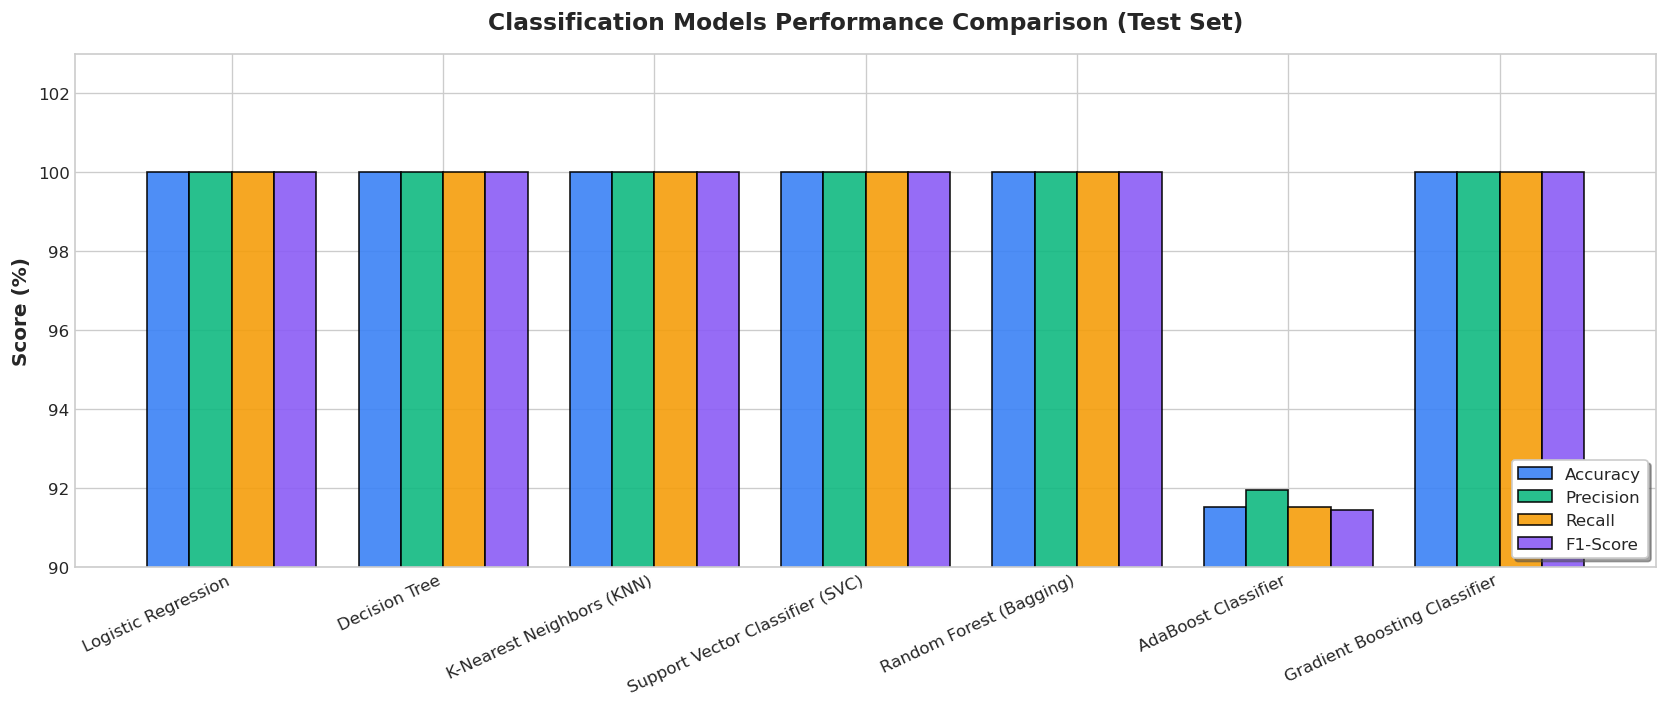

In [53]:
models_names_c = [r['Model'] for r in classification_results]
acc_c = [r['Accuracy'] * 100 for r in classification_results]
f1_c = [r['F1-score'] * 100 for r in classification_results]
prec_c = [r['Precision'] * 100 for r in classification_results]
rec_c = [r['Recall'] * 100 for r in classification_results]

x_idx = np.arange(len(models_names_c))
width = 0.2

fig, ax = plt.subplots(figsize=(14, 6))
r1 = ax.bar(x_idx - 1.5*width, acc_c, width, label='Accuracy', color='#3b82f6', edgecolor='black', alpha=0.9)
r2 = ax.bar(x_idx - 0.5*width, prec_c, width, label='Precision', color='#10b981', edgecolor='black', alpha=0.9)
r3 = ax.bar(x_idx + 0.5*width, rec_c, width, label='Recall', color='#f59e0b', edgecolor='black', alpha=0.9)
r4 = ax.bar(x_idx + 1.5*width, f1_c, width, label='F1-Score', color='#8b5cf6', edgecolor='black', alpha=0.9)

ax.set_ylabel('Score (%)', fontsize=12, fontweight='bold')
ax.set_title('Classification Models Performance Comparison (Test Set)', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x_idx)
ax.set_xticklabels(models_names_c, rotation=25, ha='right', fontsize=10)
ax.set_ylim([90, 103])
ax.legend(loc='lower right', frameon=True, shadow=True)
plt.tight_layout()
plt.show()

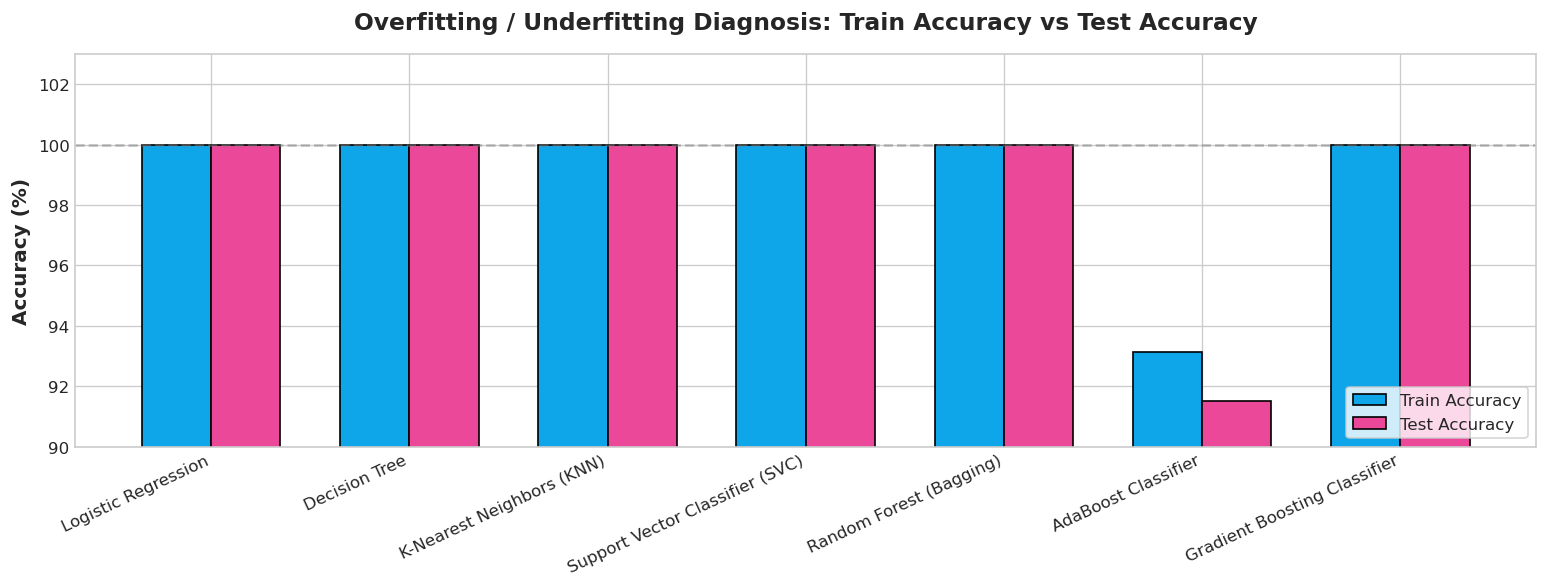

In [54]:
train_scores_c = [r['Train Score'] * 100 for r in classification_results]
test_scores_c = [r['Test Score'] * 100 for r in classification_results]

fig, ax = plt.subplots(figsize=(13, 5))
x_idx = np.arange(len(models_names_c))
width = 0.35

ax.bar(x_idx - width/2, train_scores_c, width, label='Train Accuracy', color='#0ea5e9', edgecolor='black')
ax.bar(x_idx + width/2, test_scores_c, width, label='Test Accuracy', color='#ec4899', edgecolor='black')

ax.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
ax.set_title('Overfitting / Underfitting Diagnosis: Train Accuracy vs Test Accuracy', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x_idx)
ax.set_xticklabels(models_names_c, rotation=25, ha='right', fontsize=10)
ax.set_ylim([90, 103])
ax.axhline(100, color='gray', linestyle='--', alpha=0.5)
ax.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

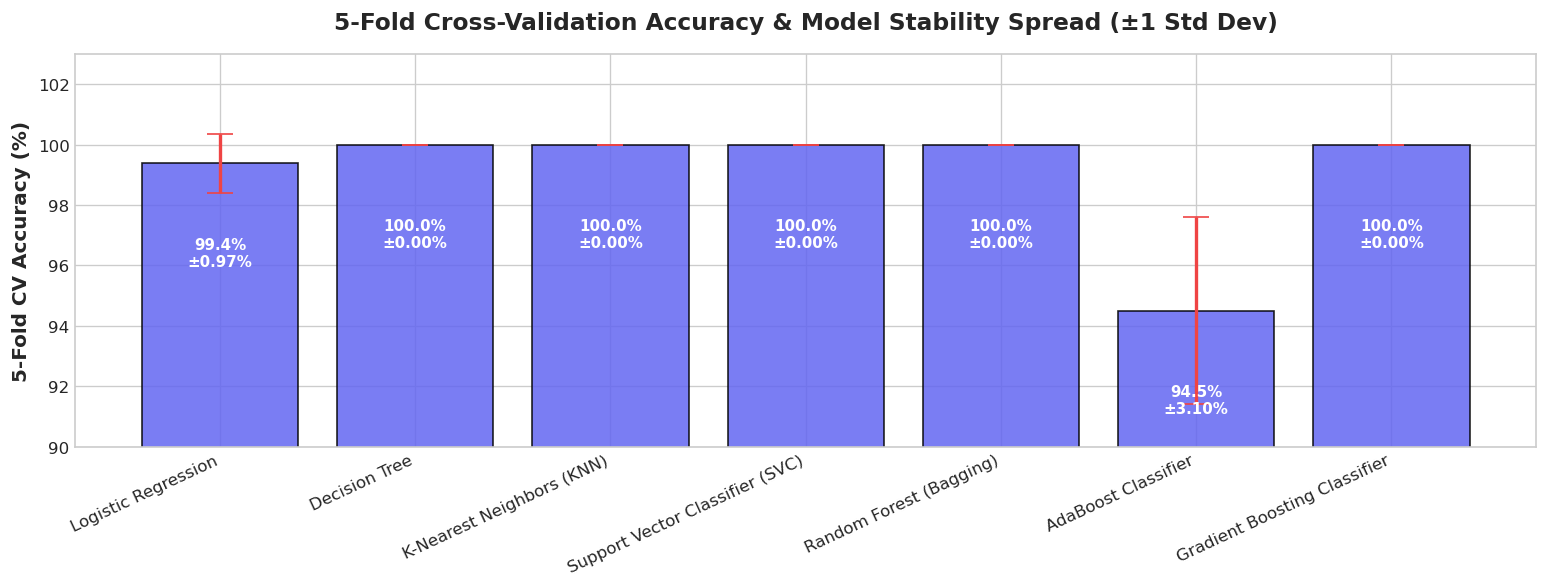

In [55]:
cv_means_c = [r['CV Mean (5-Fold)'] * 100 for r in classification_results]
cv_stds_c = [r['CV Spread (Std)'] * 100 for r in classification_results]

fig, ax = plt.subplots(figsize=(13, 5))
bars = ax.bar(models_names_c, cv_means_c, yerr=cv_stds_c, capsize=8, color='#6366f1', edgecolor='black', alpha=0.85, error_kw={'elinewidth': 2, 'ecolor': '#ef4444'})

ax.set_ylabel('5-Fold CV Accuracy (%)', fontsize=12, fontweight='bold')
ax.set_title('5-Fold Cross-Validation Accuracy & Model Stability Spread (±1 Std Dev)', fontsize=14, fontweight='bold', pad=15)
ax.set_xticklabels(models_names_c, rotation=25, ha='right', fontsize=10)
ax.set_ylim([90, 103])

for bar, mean_val, std_val in zip(bars, cv_means_c, cv_stds_c):
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval - 3.5, f"{mean_val:.1f}%\n±{std_val:.2f}%", ha='center', va='bottom', color='white', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

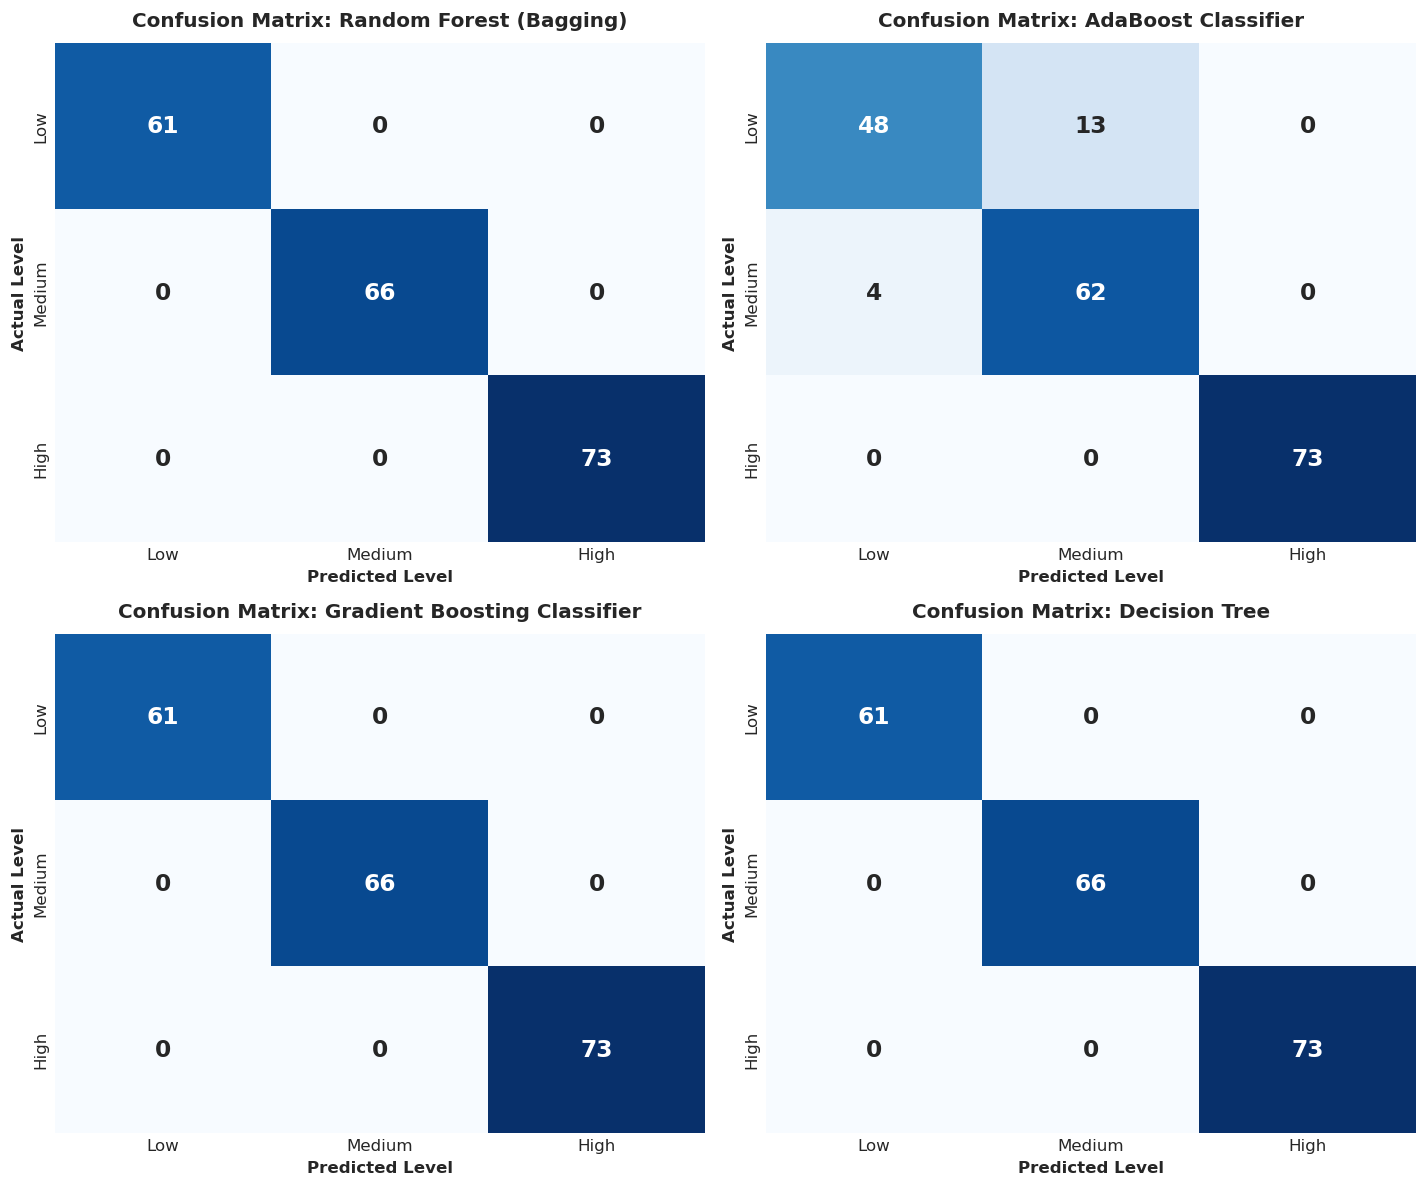

In [56]:
top_models_to_plot = [
    'Random Forest (Bagging)',
    'AdaBoost Classifier',
    'Gradient Boosting Classifier',
    'Decision Tree'
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

labels = ['Low', 'Medium', 'High']

for idx, m_name in enumerate(top_models_to_plot):
    res = next(r for r in classification_results if r['Model'] == m_name)
    cm = res['cm']
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=labels, yticklabels=labels, cbar=False,
                annot_kws={'size': 14, 'weight': 'bold'})
    axes[idx].set_title(f"Confusion Matrix: {m_name}", fontsize=12, fontweight='bold', pad=10)
    axes[idx].set_xlabel("Predicted Level", fontsize=10, fontweight='bold')
    axes[idx].set_ylabel("Actual Level", fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

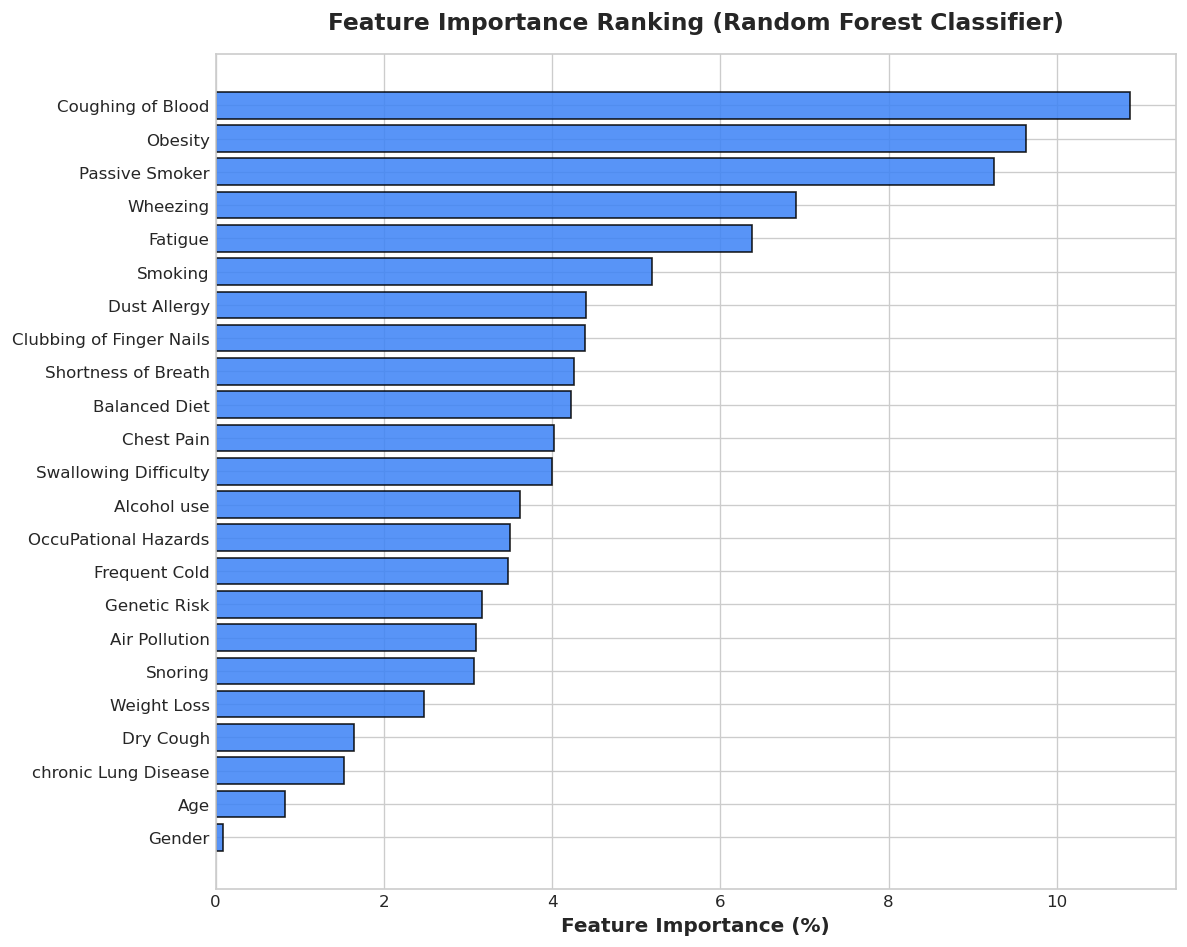

In [57]:
rf_model = next(r['model_obj'] for r in classification_results if r['Model'] == 'Random Forest (Bagging)')
importances = rf_model.feature_importances_
feat_imp_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

plt.figure(figsize=(10, 8))
plt.barh(feat_imp_df['Feature'], feat_imp_df['Importance'] * 100, color='#3b82f6', edgecolor='black', alpha=0.85)
plt.xlabel('Feature Importance (%)', fontsize=12, fontweight='bold')
plt.title('Feature Importance Ranking (Random Forest Classifier)', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()